FigS6_B branching ratio

Unique file counts per condition:
condition
Ripple            24
Ripple_Shuffle    24
Name: file, dtype: int64


C:\Users\Cornell\AppData\Local\Temp\ipykernel_51976\1680669509.py:159: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



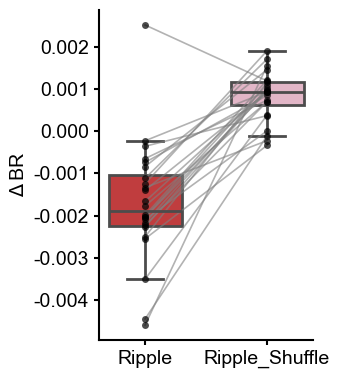

In [ ]:
import os
import pickle
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import matplotlib as mpl
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'Liberation Sans', 'DejaVu Sans', 'sans-serif']

# Make mathtext look like Arial
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Arial'
mpl.rcParams['mathtext.it'] = 'Arial:italic'
mpl.rcParams['mathtext.bf'] = 'Arial:bold' 

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
# --- Step 1: Load all files ---
import os
import glob
base_dir = r"D:\Documents\GitHub\Sleep_criticaltiy\data\rats\branching_ratio"
files = glob.glob(os.path.join(base_dir, "*_br_changes*.pkl"))

all_rows = []

# --- Step 2: Extract results ---
import numpy as np

all_rows = []

for fname in files:
    fpath = os.path.join(base_dir, fname)
    with open(fpath, "rb") as f:
        payload = pickle.load(f)

    results = payload["results"] if isinstance(payload, dict) and "results" in payload else payload

    parts = fname.split("_")
    animal = parts[3]
    day = parts[4]

    # Collect all values first (for normalization)
    file_values = []
    for key in ["ripples_br_changes", "ripples_br_changes_shuffle"]:
                # "barrage_br_changes", "barrage_br_changes_shuffle"]:
        if key in results:
            file_values.extend(results[key])

    file_values = np.array(file_values, dtype=float)
    mean_val = np.nanmean(file_values)
    std_val  = np.nanstd(file_values)

    # Avoid div by zero
    if std_val == 0:
        std_val = 1.0

    # Now add normalized rows
    for key, label in [
        ("ripples_br_changes", "Ripple"),
        ("ripples_br_changes_shuffle", "Ripple_Shuffle"),
        # ("barrage_br_changes", "Barrage"),
        # ("barrage_br_changes_shuffle", "Barrage_Shuffle"),
    ]:
        if key in results:
            vals = results[key]
            for v in vals:
                v_norm = v # z-score normalization
                all_rows.append({
                    "animal": animal,
                    "day": day,
                    "condition": label,
                    "value": v_norm
                })

# --- Step 3: Build dataframe ---
df = pd.DataFrame(all_rows)
# --- Build file identifier ---
import matplotlib as mpl

# --- Step 1: Load all files ---
df["file"] = df["animal"].astype(str) + "_" + df["day"].astype(str)
df = df.dropna(subset=["value", "animal", "day", "condition"]).copy()
# --- Compute per-file mean per condition ---
pf = (
    df.groupby(["file", "condition"], observed=True)["value"]
      .mean()
      .rename("file_mean")
      .reset_index()
)

print("Unique file counts per condition:")
print(pf.groupby("condition")["file"].nunique())
df["file"] = df["animal"].astype(str) + "_" + df["day"].astype(str)

pf = (
    df.groupby(["file", "condition"], observed=True)["value"]
      .mean()
      .rename("file_mean")
      .reset_index()
)
# Ripple subset
pf_ripple = pf[pf["condition"].isin(["Ripple", "Ripple_Shuffle"])].copy()
def draw_paired_lines(ax, df_pair, order, color="gray", alpha=0.5):
    """
    df_pair must contain columns: file, condition, file_mean
    """
    # Pivot to file → [cond1, cond2]
    pivot = df_pair.pivot_table(index="file", columns="condition", values="file_mean", observed=True)

    # Keep only files that have both conditions
    pivot = pivot.dropna()

    # Draw connecting lines
    for file_id, row in pivot.iterrows():
        ax.plot(
            [order[0], order[1]],
            [row[order[0]], row[order[1]]],
            color=color, alpha=alpha, linewidth=1.2
        )

# Barrage subset
pal_ripple = {"Ripple": "tab:red", "Ripple_Shuffle": "#e9afc6ff"}
order_ripple = ["Ripple", "Ripple_Shuffle"]


plt.figure(figsize=(3.5,4))
ax = plt.gca()

# --- Paired lines FIRST (so boxplot/stripplot draw over them) ---


# --- Boxplot ---
sns.boxplot(
    data=pf_ripple, x="condition", y="file_mean",
    order=order_ripple, palette=pal_ripple,
    showfliers=False, width=0.6, linewidth=2, ax=ax
)

# --- Points (stripplot) ---
sns.stripplot(
    data=pf_ripple, x="condition", y="file_mean",
    order=order_ripple, color="k", alpha=0.7,jitter=False,
     size=5, ax=ax
)

ax.set_xlabel("")
ax.set_ylabel(r"Δ BR")
sns.despine(top=True, right=True)
draw_paired_lines(ax, pf_ripple, order_ripple, color="gray", alpha=0.6)
plt.tight_layout()

save_path1 = r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\supplementary\individual_fig_supp\figS5_B_ripple_br_changes_perfile_paired.svg"
plt.savefig(save_path1, dpi=300)
plt.show()

In [12]:
import statsmodels.formula.api as smf

import statsmodels.formula.api as smf
import numpy as np
from scipy.stats import norm

df = df.copy()
df["animal_day"] = df["animal"].astype(str) + "_" + df["day"].astype(str)

# make categorical + set reference levels explicitly
df["animal"] = df["animal"].astype("category")
df["condition"] = df["condition"].astype(str).str.strip()
df["condition"] = pd.Categorical(df["condition"],
                                 categories=["Ripple", "Ripple_Shuffle"],  # Ripple as reference
                                 ordered=True)

df = df.dropna(subset=["value","condition","animal","animal_day"]).reset_index(drop=True)

# Mixed model: fixed condition + fixed animal; random intercept per animal_day
model = smf.mixedlm("value ~ C(condition) + C(animal)", data=df, groups=df["animal_day"], re_formula="1")
res = model.fit(method="lbfgs")

fe = res.fe_params
cov_fe = res.cov_params().loc[fe.index, fe.index]

def contrast_test(coeffs: dict, label: str):
    c = np.zeros(len(fe))
    matched = []
    for i, name in enumerate(fe.index):
        if name in coeffs:
            c[i] = coeffs[name]
            matched.append(name)
    if not matched:
        raise KeyError(f"No coeffs matched. Available terms: {list(fe.index)}")

    diff = float(c @ fe.values)
    se   = float(np.sqrt(c @ cov_fe.values @ c))
    z    = diff / se
    p    = 2 * norm.sf(abs(z))
    print(f"{label}: diff={diff:.3f}, z={z:.2f}, p={p:.4g}  (matched: {matched})")
    return diff, p

# With Ripple as reference, C(condition)[T.Ripple_Shuffle] = (Shuffle - Ripple)
# So Ripple - Shuffle = -1 * that coefficient
contrast_test({
    "C(condition)[T.Ripple_Shuffle]": -1
}, "Ripple vs Ripple_Shuffle")

c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.


Ripple vs Ripple_Shuffle: diff=-0.003, z=-19.29, p=6.637e-83  (matched: ['C(condition)[T.Ripple_Shuffle]'])


(-0.0027067836552180083, 6.636843362518647e-83)

FigS5_B probality distribution

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import nelpy as nel
import nelpy.plotting as npl
import numpy as np
import seaborn as sns
from neuro_py.io import loading
from neuro_py.plotting.figure_helpers import set_size
from neuro_py.tuning import maps
import os, re, glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------ I/O helpers ------------------
def _load_mat_any(mat_path):
    from scipy.io import loadmat
    try:
        return loadmat(mat_path, squeeze_me=True, struct_as_record=False, simplify_cells=True)
    except TypeError:
        return loadmat(mat_path, squeeze_me=True, struct_as_record=False)
    except NotImplementedError:
        import mat73
        return mat73.loadmat(mat_path)

def _to_1d_array(x):
    if x is None:
        return np.array([], dtype=float)
    arr = np.asarray(x, dtype=object)
    if arr.ndim == 0:
        return np.atleast_1d(arr).astype(float, copy=False)
    try:
        return np.asarray(arr).ravel().astype(float, copy=False)
    except (ValueError, TypeError):
        return np.array([float(v) for v in np.ravel(arr)], dtype=float)

def _to_state_str(s):
    try:
        if isinstance(s, (bytes, bytearray)):
            return s.decode('utf-8', 'ignore')
        if isinstance(s, str):
            return s
        arr = np.asarray(s)
        if arr.ndim == 0:
            return str(arr.item())
        return ''.join(arr.tolist()) if arr.dtype.kind in ('U','S') else str(arr)
    except Exception:
        return str(s)

def _infer_animal_day_from_path(basepath):
    base = os.path.basename(basepath.rstrip("\\/"))
    animal = os.path.basename(os.path.dirname(basepath))
    mday = re.search(r"day(\d+)", base, flags=re.I)
    day = int(mday.group(1)) if mday else None
    return animal, day

# ------------------ extract center_s + d2 ------------------
def _extract_center_d2_by_state_from_mat(mat_path, region=None, animal=None, day=None):
    """
    Returns DataFrame with columns:
      state, center_s, d2, region, animal, day
    """
    mat = _load_mat_any(mat_path)
    results = mat.get("results", None)
    if results is None:
        return pd.DataFrame(columns=["state","center_s","d2","region","animal","day"])

    if isinstance(results, dict):
        iter_results = list(results.values())
    else:
        iter_results = list(results if isinstance(results, (list, tuple)) else np.atleast_1d(results))

    rows = []
    for it in iter_results:
        if hasattr(it, "get"):
            st = _to_state_str(it.get("state", "UNKNOWN"))
            c_raw = it.get("center", [])
            d2_raw = it.get("d2", [])
        elif isinstance(it, dict) or hasattr(it, "__getitem__"):
            st = _to_state_str(it.get("state", it["state"] if "state" in it else "UNKNOWN"))
            c_raw = it.get("center", it["center"] if "center" in it else [])
            d2_raw = it.get("d2", it["d2"] if "d2" in it else [])
        else:
            st, c_raw, d2_raw = "UNKNOWN", [], []

        centers = _to_1d_array(c_raw)
        d2_vals = _to_1d_array(d2_raw)
        ok = np.isfinite(centers) & np.isfinite(d2_vals)
        centers, d2_vals = centers[ok], d2_vals[ok]
        if centers.size == 0:
            continue

        st_up = _to_state_str(st).upper()
        if st_up == "WAKE":
            st_up = "AWAKE"
        if st_up not in ("NREM", "AWAKE", "REM"):
            continue

        rows.append(pd.DataFrame({
            "state": st_up,
            "center_s": centers.astype(float, copy=False),
            "d2": d2_vals.astype(float, copy=False),
            "region": region if region else "",
            "animal": animal if animal else "",
            "day": day if day is not None else ""
        }))

    return pd.concat(rows, ignore_index=True) if rows else pd.DataFrame(
        columns=["state","center_s","d2","region","animal","day"]
    )

def load_center_d2_from_session(basepath, region):
    """
    Loads newest 30s and newest 60s files (if any) and returns pooled
    center_s + d2 with a 'window' column ∈ {'30s','60s'}.
    """
    region = region.upper()
    search_dir = Path(basepath) / "complex_system"
    if not search_dir.exists():
        return pd.DataFrame(columns=["state","center_s","d2","window","region","animal","day"])

    pats = {
        "30s": f"*_{region}_D2_time_resolved_error_bar.mat",
    }
    animal, day = _infer_animal_day_from_path(basepath)

    out = []
    for win_label, pat in pats.items():
        files = glob.glob(str(search_dir / pat))
        if not files:
            continue
        mat_path = max(files, key=os.path.getmtime)
        df = _extract_center_d2_by_state_from_mat(mat_path, region=region, animal=animal, day=day)
        if df.empty:
            continue
        df["window"] = win_label
        out.append(df)

    return pd.concat(out, ignore_index=True) if out else pd.DataFrame(
        columns=["state","center_s","d2","window","region","animal","day"]
    )

# --- compute per-row durations from timestamps (not median step) ---
def add_duration_from_timestamps(df, fill_last="median"):
    """
    For each (animal, day, window, state), sort by center_s and compute row-wise
    duration as the forward difference: duration[i] = center[i+1] - center[i].
    The last row per group gets:
        - fill_last="median": group's median Δt
        - fill_last="drop": NaN (will be dropped later)
        - fill_last=float: a constant seconds value
    Returns a copy with a new 'duration_s' column.
    """
    d = df.copy()
    grp_cols = ["animal","day","window","state"]

    def _durations(g):
        g = g.sort_values("center_s")
        c = g["center_s"].to_numpy(dtype=float)
        dt = np.empty_like(c, dtype=float)
        if c.size == 1:
            dt[:] = np.nan
        else:
            dt[:-1] = np.diff(c)
            # last-row handling
            if fill_last == "median":
                med = np.nanmedian(dt[:-1]) if dt.size > 1 else np.nan
                dt[-1] = med if np.isfinite(med) and med > 0 else np.nan
            elif fill_last == "drop":
                dt[-1] = np.nan
            else:
                # numeric
                try:
                    dt[-1] = float(fill_last)
                except Exception:
                    dt[-1] = np.nan
        # negative/zero dt are invalid
        dt[~np.isfinite(dt) | (dt <= 0)] = np.nan
        g["duration_s"] = dt
        return g

    d = d.groupby(grp_cols, observed=True, group_keys=False).apply(_durations)
    # drop rows with no valid duration
    d = d[np.isfinite(d["duration_s"]) & (d["duration_s"] > 0)]
    return d

def compute_equal_width_bins(d, n_bins=10, by_window=False):
    """
    Equal-width bins on D² within each state (and optionally state×window).
    Adds 'd2_bin' ∈ {1..n_bins} as nullable Int64.
    Returns df_with_bins, edges_map.
    """
    d = d.copy()

    # Make sure d2 is numeric
    d["d2"] = pd.to_numeric(d["d2"], errors="coerce")

    # Pre-create a nullable integer column to avoid dtype thrash
    d["d2_bin"] = pd.Series([pd.NA] * len(d), dtype="Int64")

    edges_map = {}
    groups = (
        d.groupby(["state", "window"], observed=True)
        if by_window else
        d.groupby(["state"], observed=True)
    )

    for key, g in groups:
        idx = g.index
        vals = d.loc[idx, "d2"].to_numpy()

        if vals.size == 0 or not np.isfinite(vals).any():
            continue

        dmin, dmax = float(np.nanmin(vals)), float(np.nanmax(vals))
        if not np.isfinite(dmin) or not np.isfinite(dmax) or dmin == dmax:
            # degenerate case: single bin
            edges = np.array([dmin - 1e-12, dmax + 1e-12], dtype=float)
        else:
            edges = np.linspace(dmin, dmax, n_bins + 1, dtype=float)

        edges_map[key] = edges

        # labels=False -> integer codes [0..n_bins-1], NaN for out-of-bin
        codes = pd.cut(
            d.loc[idx, "d2"],
            bins=edges,
            labels=False,
            include_lowest=True
        )

        # Convert to nullable Int64 with 1-based labels
        # Note: adding 1 keeps NA as NA with pandas nullable integers
        codes = (pd.Series(codes, index=idx, dtype="Int64") + 1).astype("Int64")

        # Single assignment of a clean integer Series
        d.loc[idx, "d2_bin"] = codes

    # Ensure final dtype
    d["d2_bin"] = d["d2_bin"].astype("Int64")
    return d, edges_map

def aggregate_durations_by_bin(
    d,
    by_window=False,
    include_env=False,
    normalize_within="state",   # "state" or None
):
    """
    Sum durations per d2_bin, grouped by:
        - state
        - d2_bin
        - [environment] (optional)
        - [window]      (optional)

    If include_env=False, `environment` is ignored and not in the output.

    normalize_within:
        - "state": normalize within each (state, [window], [environment if included])
        - None: keep absolute seconds
    """
    d = d.copy()

    # ---- GROUPING KEYS ----
    keys = ["state", "d2_bin"]
    if include_env and ("environment" in d.columns):
        keys.append("environment")
    if by_window and ("window" in d.columns):
        keys.append("window")

    # ---- AGGREGATE ----
    agg = (
        d.dropna(subset=["d2_bin", "duration_s"])
         .groupby(keys, observed=True)["duration_s"]
         .sum()
         .rename("dwell_sec_total")
         .reset_index()
    )

    # ---- NORMALIZATION ----
    if normalize_within == "state":
        norm_keys = ["state"]
        if by_window and ("window" in agg.columns):
            norm_keys.append("window")
        if include_env and ("environment" in agg.columns):
            norm_keys.append("environment")

        agg["dwell_frac"] = agg.groupby(norm_keys)["dwell_sec_total"].transform(
            lambda x: x / x.sum() if x.sum() > 0 else x
        )

    return agg


def plot_histograms(agg, by_window=False, use_fraction=True, n_bins=10, title=None, save_path=None):
    """
    Bar histograms of dwell (fraction or seconds) vs D² bin for each state.
    If by_window=True, facet by 30s/60s columns.
    """
    order_states = ["NREM","AWAKE","REM"]
    ycol = "dwell_frac" if use_fraction else "dwell_sec_total"
    ylab = "Dwell fraction" if use_fraction else "Total dwell (s)"

    if by_window and "window" in agg.columns:
        order_windows = ["30s"]
        windows = [w for w in order_windows if w in agg["window"].unique()]
        fig, axes = plt.subplots(len(order_states), len(windows), figsize=(5*len(windows), 3.8*len(order_states)),
                                 sharex=True, sharey=True)
        if len(order_states) == 1: axes = np.atleast_2d(axes)
        for i, st in enumerate(order_states):
            for j, w in enumerate(windows):
                ax = axes[i, j]
                sub = agg[(agg["state"]==st) & (agg["window"]==w) & agg["d2_bin"].notna()]
                if sub.empty:
                    ax.set_title(f"{st} – {w} (no data)")
                    continue
                ax.bar(sub["d2_bin"].astype(int), sub[ycol], width=0.7, edgecolor="black")
                if i == 0: ax.set_title(w, fontweight="bold")
                if j == 0: ax.set_ylabel(f"{st}\n{ylab}")
                ax.set_xlabel("D² bin")
                ax.set_xticks(range(1, n_bins+1))
                ax.spines["top"].set_visible(False)
                ax.spines["right"].set_visible(False)
        plt.suptitle(title or "Dwell vs D² bins (by window)", fontweight="bold")
    else:
        fig, axes = plt.subplots(1, len(order_states), figsize=(5*len(order_states), 4), sharey=True)
        if len(order_states) == 1: axes = [axes]
        for ax, st in zip(axes, order_states):
            sub = agg[(agg["state"]==st) & agg["d2_bin"].notna()]
            if sub.empty:
                ax.set_title(f"{st} (no data)")
                continue
            ax.bar(sub["d2_bin"].astype(int), sub[ycol], width=0.7, edgecolor="black")
            ax.set_title(st, fontweight="bold")
            ax.set_xlabel("D² bin")
            ax.set_xticks(range(1, n_bins+1))
            if ax is axes[0]: ax.set_ylabel(ylab)
            ax.spines["top"].set_visible(False)
            ax.spines["right"].set_visible(False)
        plt.suptitle(title or "Dwell vs D² bins (pooled)", fontweight="bold")

    plt.tight_layout(rect=[0,0,1,0.95])
    if save_path:
        Path(save_path).parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(save_path, dpi=300)
        print(f"Saved: {save_path}")
    plt.show()


# ------------------ DRIVER ------------------
# Your session folders:
paths = [
 
r"V:\data\hpc_ctx_project\HP17\hp17_day2_20250413",
r"V:\data\hpc_ctx_project\HP17\hp17_day23_20250507",
r"V:\data\hpc_ctx_project\HP17\hp17_day26_20250510",
r"V:\data\hpc_ctx_project\HP17\hp17_day32_20250516",
r"V:\data\hpc_ctx_project\HP17\hp17_day34_20250518",
r"V:\data\hpc_ctx_project\HP17\hp17_day36_20250520",
r"V:\data\hpc_ctx_project\HP17\hp17_day40_20250526",
r"V:\data\hpc_ctx_project\HP15\hp15_day35_20250205",
r"V:\data\hpc_ctx_project\HP18\hp18_day13_20250417",
r"V:\data\hpc_ctx_project\HP18\hp18_day16_20250420",
r"V:\data\hpc_ctx_project\HP18\hp18_day17_20250421",
r"V:\data\hpc_ctx_project\HP18\hp18_day36_20250510",
r"V:\data\hpc_ctx_project\HP18\hp18_day40_20250514",
r"V:\data\hpc_ctx_project\HP18\hp18_day48_20250522",
r"V:\data\hpc_ctx_project\HP18\hp18_day49_20250523",
r"V:\data\hpc_ctx_project\HP18\hp18_day55_20250529",
r"S:\data\latentseq\RM10\rm10_day6_20250810",
r"S:\data\latentseq\RM10\rm10_day10_20250814",
r"S:\data\latentseq\RM10\rm10_day11_20250815",
r"S:\data\latentseq\RM10\rm10_day12_20250817",
r"U:\data\HMC\HMC1\day8",
r"U:\data\HMC\HMC1\day9",
r"U:\data\HMC\HMC1\day10",
r"U:\data\HMC\HMC1\day11",
]
regions = ["CA1"]  # change if needed
save_root = r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan\rats"

def _find_state_mat(basepath):
    """
    Heuristics to locate a MAT file holding state_dict/THETA.
    Searches common names in basepath and subfolders.
    """
    candidates = []
    basepath = Path(basepath)
    # common names / locations; extend as needed
    pats = [
        "*state*.mat",
        "*State*.mat",
        "states.mat",
        "state_dict.mat",
        "sleep_states.mat",
        str(basepath / "complex_system" / "*state*.mat"),
        str(basepath / "complex_system" / "state_dict.mat"),
    ]
    for pat in pats:
        candidates.extend(glob.glob(str(basepath / pat) if not pat.startswith(str(basepath)) else pat))
    # fall back: any .mat in basepath
    if not candidates:
        candidates.extend(glob.glob(str(basepath / "*.mat")))
    # pick the newest that actually contains THETA
    best = None
    best_mtime = -1
    for p in candidates:
        try:
            m = _load_mat_any(p)
            # look for THETA under state_dict or top-level
            has_theta = False
            if "state_dict" in m and isinstance(m["state_dict"], dict):
                has_theta = "THETA" in m["state_dict"]
            if ("THETA" in m) or has_theta:
                mt = os.path.getmtime(p)
                if mt > best_mtime:
                    best, best_mtime = p, mt
        except Exception:
            continue
    return best  # may be None


def load_theta_epochs(basepath):
    """
    Returns Nx2 float array of [start, stop] seconds for THETA epochs,
    or an empty (0,2) array if not found.
    """
    state_dict = loading.load_SleepState_states(basepath)
    theta_epochs = nel.EpochArray(
    state_dict["THETA"],
    )
    arr = np.asarray(theta_epochs.data, float)
    return arr
def annotate_with_epochs(df_session, epoch_df):
    """
    For each row in df_session, assign:
        - epoch_name: which epoch its center_s falls into
        - environment: epoch_df['environment'] for that epoch

    epoch_df is expected to have columns: 'name', 'startTime', 'stopTime', 'environment'.
    """
    d = df_session.copy()

    if d.empty or epoch_df is None or len(epoch_df) == 0:
        d["epoch_name"] = pd.NA
        d["environment"] = pd.NA
        return d

    # Extract arrays
    names = epoch_df["name"].astype(str).to_numpy()
    starts = pd.to_numeric(epoch_df["startTime"], errors="coerce").to_numpy(float)
    stops  = pd.to_numeric(epoch_df["stopTime"],  errors="coerce").to_numpy(float)
    envs   = epoch_df.get("environment", pd.Series([""] * len(epoch_df))).astype(str).to_numpy()
    manipulation=epoch_df.get("manipulation", pd.Series([""] * len(epoch_df))).astype(str).to_numpy()

    # Sort epochs by start time (assumed non-overlapping)
    order = np.argsort(starts)
    starts = starts[order]
    stops  = stops[order]
    names  = names[order]
    envs   = envs[order]
    manipulation = manipulation[order]

    centers = pd.to_numeric(d["center_s"], errors="coerce").to_numpy(float)

    # For each center: find rightmost start <= center, then check center < stop
    idx = np.searchsorted(starts, centers, side="right") - 1
    valid = (idx >= 0) & (centers < stops[np.clip(idx, 0, len(stops)-1)])

    epoch_name = np.full(centers.shape, None, dtype=object)
    environment = np.full(centers.shape, None, dtype=object)

    good_idx = np.where(valid)[0]
    if good_idx.size > 0:
        epoch_idx = idx[good_idx]
        epoch_name[good_idx] = names[epoch_idx]
        environment[good_idx] = envs[epoch_idx]
        manipulation_good = manipulation[epoch_idx]
    d["epoch_name"] = pd.Series(epoch_name, index=d.index, dtype="object")
    d["environment"] = pd.Series(environment, index=d.index, dtype="object")
    d["manipulation"] = pd.Series(manipulation_good, index=d.index, dtype="object")

    return d


def centers_in_intervals_bool(centers, intervals):
    """
    Vectorized: for each center (1D), test if it falls within ANY [start,stop) row in intervals (Nx2).
    Assumes intervals are unsorted; we sort once.
    """
    centers = np.asarray(centers, float)
    if intervals.size == 0 or centers.size == 0:
        return np.zeros_like(centers, dtype=bool)
    starts = np.asarray(intervals[:,0], float)
    stops  = np.asarray(intervals[:,1], float)
    order = np.argsort(starts)
    starts = starts[order]
    stops  = stops[order]
    # For each center c: find the rightmost start <= c, then check c < corresponding stop
    idx = np.searchsorted(starts, centers, side="right") - 1  # -1 if all starts > c
    ok = (idx >= 0) & (centers < stops[np.clip(idx, 0, len(stops)-1)])
    return ok


def split_wake_into_theta_nontheta(df_session, theta_intervals):
    """
    Takes a single-session DataFrame with columns ['state','center_s', ...].
    Returns a copy where AWAKE rows are split into 'THETA' or 'nonTHETA'
    based on whether center_s ∈ theta_intervals.
    """
    d = df_session.copy()
    awake_mask = d["state"].astype(str).str.upper().eq("AWAKE")
    if awake_mask.any() and theta_intervals.size > 0:
        c = d.loc[awake_mask, "center_s"].to_numpy(float)
        in_theta = centers_in_intervals_bool(c, theta_intervals)
        # assign new state labels
        new_state = d.loc[awake_mask, "state"].copy()
        new_state.values[:] = "nonTHETA"
        new_state.values[in_theta] = "THETA"
        d.loc[awake_mask, "state"] = new_state.values
    else:
        # no θ-epochs found → leave AWAKE as nonTHETA
        d.loc[awake_mask, "state"] = "nonTHETA"
    return d
# --- DRIVER ---


pooled = []
missing = []
for basepath in paths:
    for reg in regions:
        try:
            df_sess = load_center_d2_from_session(basepath, reg)
            if df_sess.empty:
                missing.append((basepath, reg))
                continue

            # Split AWAKE → THETA / nonTHETA
            theta_ep = load_theta_epochs(basepath)    # Nx2
            df_sess = split_wake_into_theta_nontheta(df_sess, theta_ep)

            # load epoch table and annotate each row
            try:
                epoch_df = loading.load_epoch(str(basepath))
            except Exception as e_ep:
                print(f"⚠️ Failed to load epoch for {basepath}: {e_ep}")
                epoch_df = None

            df_sess = annotate_with_epochs(df_sess, epoch_df)

            pooled.append(df_sess)
        except Exception as e:
            print(f"⚠️ {reg} @ {basepath}: {e}")
            missing.append((basepath, reg))

if not pooled:
    raise RuntimeError("No usable sessions found.")

df_all = pd.concat(pooled, ignore_index=True)

# 1) durations from timestamps
df_all = add_duration_from_timestamps(df_all)   # creates 'duration_s'

# 2) equal-width bins (now per state label that includes THETA/nonTHETA)
N_BINS = 15
BY_WIN = True
df_binned, edges = compute_equal_width_bins(df_all, n_bins=N_BINS, by_window=BY_WIN)

C:\Users\Cornell\AppData\Local\Temp\ipykernel_51976\3119825907.py:187: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.


In [5]:
df_all

,state,center_s,d2,region,animal,day,window,epoch_name,environment,manipulation,duration_s
0,NREM,1426.0,0.129548,CA1,HP17,2,30s,hp17_presleep_250413_140955,sleep,nan,2.0
1,NREM,1428.0,0.129773,CA1,HP17,2,30s,hp17_presleep_250413_140955,sleep,nan,2.0
2,NREM,1430.0,0.126277,CA1,HP17,2,30s,hp17_presleep_250413_140955,sleep,nan,2.0
3,NREM,1432.0,0.129190,CA1,HP17,2,30s,hp17_presleep_250413_140955,sleep,nan,2.0
4,NREM,1434.0,0.141834,CA1,HP17,2,30s,hp17_presleep_250413_140955,sleep,nan,56.0
...,...,...,...,...,...,...,...,...,...,...,...
206556,THETA,23787.0,0.155182,CA1,HMC1,8,30s,postSleep_210411_103522,sleep,nan,2.0
206557,nonTHETA,23789.0,0.116430,CA1,HMC1,8,30s,postSleep_210411_103522,sleep,nan,2.0
206558,nonTHETA,23791.0,0.125182,CA1,HMC1,8,30s,postSleep_210411_103522,sleep,nan,2.0
206559,nonTHETA,23793.0,0.145695,CA1,HMC1,8,30s,postSleep_210411_103522,sleep,nan,2.0


Saved KDE: D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\supplementary\individual_fig_supp\figS5_B_rat_d2_density_sleep_wake.svg


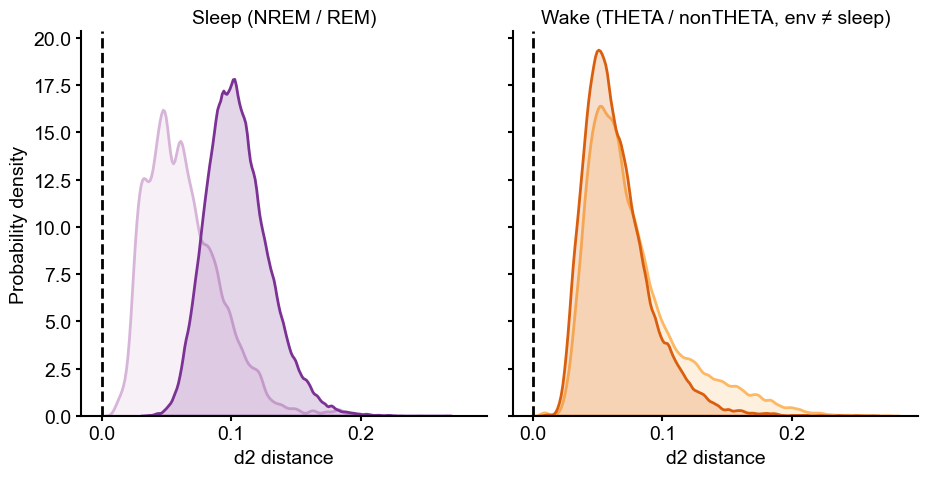

C:\Users\Cornell\AppData\Local\Temp\ipykernel_51976\2398605226.py:204: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

C:\Users\Cornell\AppData\Local\Temp\ipykernel_51976\2398605226.py:223: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



Saved boxplots: D:/Documents/GitHub/Sleep_criticaltiy/reports/new_planc/supplementary/individual_fig_supp/figS5_B_rat_d2_density_sleep_wake_boxplots.svg


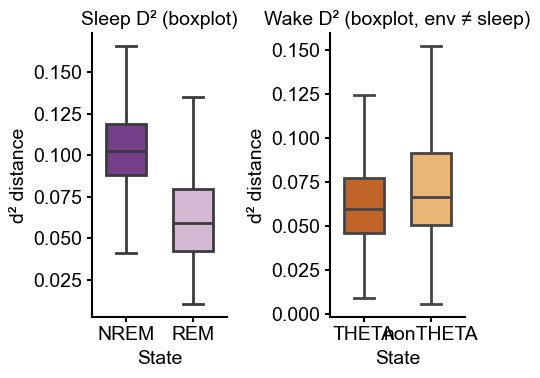

c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.


           Mixed Linear Model Regression Results
Model:              MixedLM Dependent Variable: d2         
No. Observations:   83386   Method:             REML       
No. Groups:         4       Scale:              0.0005     
Min. group size:    3386    Log-Likelihood:     198690.6137
Max. group size:    39793   Converged:          Yes        
Mean group size:    20846.5                                
-----------------------------------------------------------
                Coef.  Std.Err.    z    P>|z| [0.025 0.975]
-----------------------------------------------------------
Intercept        0.102    0.004  25.051 0.000  0.094  0.110
C(state)[T.REM] -0.041    0.000 -95.010 0.000 -0.041 -0.040
Group Var        0.000    0.002                            
animal_day Var   0.000    0.001                            

            Mixed Linear Model Regression Results
Model:               MixedLM  Dependent Variable:  d2         
No. Observations:    45460    Method:              REML  

c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.


In [9]:
import numpy as np
from scipy.stats import gaussian_kde
import matplotlib as mpl

import matplotlib as mpl

# Global font: prefer Arial, with safe fallbacks
mpl.rcParams['svg.fonttype'] = 'none' 
mpl.rcParams['text.usetex'] = False
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = [
    'Helvetica Neue', 'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
]

# Mathtext to match
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Helvetica Neue'   # or 'Helvetica'
mpl.rcParams['mathtext.it'] = 'Helvetica Neue:italic'
mpl.rcParams['mathtext.bf'] = 'Helvetica Neue:bold'

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
def prepare_for_lmm(df):
    df = df.copy()
    df["animal_day"] = df["animal"].astype(str) + "_day" + df["day"].astype(str)
    df["state"] = df["state"].astype("category")
    return df
def print_lmm_key_stats(model, label="Model"):
    """
    Print only essential parameters from a fitted MixedLM model:
    effect size, SE, p-value, and 95% CI.
    """
    params = model.params
    bse = model.bse
    pvals = model.pvalues
    ci = model.conf_int()
    
    print(f"\n=== {label}: Key Statistics ===")
    for term in params.index:
        if term == "Intercept":
            continue  # optional: ignore intercept

        est = params[term]
        se  = bse[term]
        p   = pvals[term]
        lo, hi = ci.loc[term]

        print(f"{term}:")
        print(f"  β = {est:.4f}")
        print(f"  SE = {se:.4f}")
        print(f"  p = {p:.4e}")
        print(f"  95% CI = [{lo:.4f}, {hi:.4f}]")

def plot_density_split(df, by_window=False, title=None, save_path=None, bw_adjust=0.5):
    """
    KDE of D² (x) with each window equally weighted, colored by state.

    If THETA/nonTHETA + 'environment' are present, plot two KDE subplots:
        - left: sleep (NREM, REM)
        - right: wake (THETA, nonTHETA) with environment != 'sleep'

    Also makes a second figure with boxplots of D²:
        - sleep: NREM vs REM
        - wake: THETA vs nonTHETA (env != sleep)

    Otherwise, fall back to a single-panel KDE + single boxplot over all states.
    """
    states = df["state"].astype(str)
    have_theta = states.isin(["THETA", "nonTHETA"]).any()

    # basic palettes
    sleep_palette = {"NREM": "#7b3294", "REM": "#d7b5d8"}
    wake_palette  = {"THETA": "#d95f0e", "nonTHETA": "#fdb863"}
    all_palette   = {**sleep_palette, **wake_palette, "AWAKE": "#d9f0d3"}

    # --- Clean / filter base df ---
    df_plot = df[df["d2"].notna()].copy()
    if df_plot.empty:
        print("No data to plot for density plot.")
        return

    # Decide if we can do the sleep/wake split
    do_split = have_theta and ("environment" in df_plot.columns) and not by_window

    if do_split:
        # ------------------ SPLIT VERSION ------------------
        env = df_plot["environment"].astype(str).str.lower()
        manipulation=df_plot["manipulation"].astype(str).str.lower()

        df_sleep = df_plot[df_plot["state"].isin(["NREM", "REM"])& (manipulation != "pcf_silence") ].copy()
        df_wake  = df_plot[
            df_plot["state"].isin(["THETA", "nonTHETA"]) &
            (env != "sleep")
        ].copy()
        if df_sleep.empty and df_wake.empty:
            print("No data to plot for sleep/wake split.")
            return

        # ===== KDE FIGURE =====
        fig, axes = plt.subplots(1, 2, figsize=(9.5, 5), sharey=True,sharex=True)
        ax_sleep, ax_wake = axes

        # ---- Sleep panel ----
        if not df_sleep.empty:
            sns.kdeplot(
                data=df_sleep,
                x="d2",
                hue="state",
                hue_order=[s for s in ["NREM", "REM"] if s in df_sleep["state"].unique()],
                palette=sleep_palette,
                weights=None,
                fill=True,
                alpha=0.2,
                common_norm=False,
                bw_adjust=bw_adjust,
                linewidth=2,
                ax=ax_sleep,
            )
            ax_sleep.set_title("Sleep (NREM / REM)")
            ax_sleep.set_xlabel("d2 distance")
            ax_sleep.set_ylabel("Probability density")
            leg = ax_sleep.get_legend()
            if leg is not None:
                leg.remove()
            ax_sleep.spines["top"].set_visible(False)
            ax_sleep.spines["right"].set_visible(False)
            ax_sleep.axvline(0, ls="--", lw=2, color="k")
        else:
            ax_sleep.set_visible(False)

        # ---- Wake panel ----
        if not df_wake.empty:
            sns.kdeplot(
                data=df_wake,
                x="d2",
                hue="state",
                hue_order=[s for s in ["THETA", "nonTHETA"] if s in df_wake["state"].unique()],
                palette=wake_palette,
                weights=None,
                fill=True,
                alpha=0.2,
                common_norm=False,
                bw_adjust=bw_adjust,
                linewidth=2,
                ax=ax_wake,
            )
            ax_wake.set_title("Wake (THETA / nonTHETA, env ≠ sleep)")
            ax_wake.set_xlabel("d2 distance")
            ax_wake.set_ylabel("Probability density")
            leg = ax_wake.get_legend()
            if leg is not None:
                leg.remove()
            ax_wake.spines["top"].set_visible(False)
            ax_wake.spines["right"].set_visible(False)
            ax_wake.axvline(0, ls="--", lw=2, color="k")
        else:
            ax_wake.set_visible(False)

        if title:
            fig.suptitle(title, fontweight="bold")
            fig.subplots_adjust(top=0.88)

        plt.tight_layout()

        if save_path is not None:
            Path(save_path).parent.mkdir(parents=True, exist_ok=True)
            plt.savefig(save_path, dpi=300)
            print(f"Saved KDE: {save_path}")

        plt.show()

        # ===== BOX PLOT FIGURE =====
        fig2, axes2 = plt.subplots(1, 2, figsize=(5, 4), sharey=False)
        ax_bx_sleep, ax_bx_wake = axes2

        # Sleep boxplot
        if not df_sleep.empty:
            sleep_order = [s for s in ["NREM", "REM"] if s in df_sleep["state"].unique()]
            sns.boxplot(
                data=df_sleep,
                x="state",
                y="d2",
                order=sleep_order,
                palette=sleep_palette,
                ax=ax_bx_sleep,showfliers=False,width=0.6,linewidth=2
            )
            ax_bx_sleep.set_title("Sleep D² (boxplot)")
            ax_bx_sleep.set_xlabel("State")
            ax_bx_sleep.set_ylabel("d² distance")
            ax_bx_sleep.spines["top"].set_visible(False)
            ax_bx_sleep.spines["right"].set_visible(False)
        else:
            ax_bx_sleep.set_visible(False)

        # Wake boxplot
        if not df_wake.empty:
            wake_order = [s for s in ["THETA", "nonTHETA"] if s in df_wake["state"].unique()]
            sns.boxplot(
                data=df_wake,
                x="state",
                y="d2",
                order=wake_order,
                palette=wake_palette,
                ax=ax_bx_wake,showfliers=False,width=0.6,linewidth=2
            )
            ax_bx_wake.set_title("Wake D² (boxplot, env ≠ sleep)")
            ax_bx_wake.set_xlabel("State")
            ax_bx_wake.set_ylabel("d² distance")
            ax_bx_wake.spines["top"].set_visible(False)
            ax_bx_wake.spines["right"].set_visible(False)
        else:
            ax_bx_wake.set_visible(False)

        plt.tight_layout()

        if save_path is not None:
            box_path = str(Path(save_path).with_suffix("").as_posix()) + "_boxplots.svg"
            plt.savefig(box_path, dpi=300)
            print(f"Saved boxplots: {box_path}")

        plt.show()

    import statsmodels.formula.api as smf

    # --- Sleep: NREM vs REM ---
    df_s = prepare_for_lmm(df_sleep).copy()
    df_s = df_s[df_s["state"].isin(["NREM", "REM"])].copy()

    df_s["animal"] = df_s["animal"].astype("category")
    df_s["animal_day"] = df_s["animal_day"].astype("category")
    df_s["state"] = df_s["state"].astype("category")
    df_s = df_s.dropna(subset=["d2","state","animal","animal_day"]).reset_index(drop=True)

    vc = {"animal_day": "0 + C(animal_day)"}  # nested session/day intercepts

    model_sleep = smf.mixedlm(
        "d2 ~ C(state)",
        data=df_s,
        groups=df_s["animal"],      # subject-level
        vc_formula=vc,
        re_formula="1"
    ).fit(method="lbfgs")

    print(model_sleep.summary())
    import statsmodels.formula.api as smf

    df_w = prepare_for_lmm(df_wake).copy()
    df_w = df_w[df_w["state"].isin(["THETA", "nonTHETA"])].copy()

    # make sure types are clean
    df_w["animal"] = df_w["animal"].astype("category")
    df_w["animal_day"] = df_w["animal_day"].astype("category")

    # set reference level (optional but recommended)
    df_w["state"] = df_w["state"].astype(str).str.strip()
    df_w["state"] = pd.Categorical(df_w["state"], categories=["THETA", "nonTHETA"], ordered=True)

    df_w = df_w.dropna(subset=["d2", "state", "animal", "animal_day"]).reset_index(drop=True)

    # nested session/day intercepts
    vc = {"animal_day": "0 + C(animal_day)"}

    model_wake = smf.mixedlm(
        "d2 ~ C(state)",
        data=df_w,
        groups=df_w["animal"],      # subject-level random intercept
        vc_formula=vc,              # nested animal_day intercept
        re_formula="1"
    ).fit(method="lbfgs")

    print(model_wake.summary())
    print_lmm_key_stats(model_sleep, "Sleep (NREM vs REM)")
    print_lmm_key_stats(model_wake, "Wake (THETA vs nonTHETA)")
    # ------------------ FALLBACK: single-panel version ------------------
    if have_theta:
        order_states = ["NREM", "REM", "THETA", "nonTHETA"]
    else:
        order_states = ["NREM", "AWAKE", "REM"]

    df_plot = df_plot[df_plot["state"].isin(order_states)].copy()
    if df_plot.empty:
        print("No data to plot for density plot (after state filter).")
        return

df_30s_only = df_binned[df_binned["window"] == "30s"].copy()

if df_30s_only.empty:
    print("No 30s window data found to plot.")
else:
    plot_density_split(
        df_30s_only,
        by_window=False,
        title=None,
        save_path=r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\supplementary\individual_fig_supp\figS5_B_rat_d2_density_sleep_wake.svg",
        bw_adjust=0.5,
    )


S6_D_ISI entropy

      center_s        d2    d2_err state         MUA  n_cell  isi_entropy  \
0       4112.0  0.137081  0.037001  NREM  116.733333     127     4.872529   
1       4114.0  0.160064  0.039420  NREM  121.516667     127     4.858376   
2       4116.0  0.172581  0.040097  NREM  126.216667     127     4.851734   
3       4118.0  0.175482  0.039707  NREM  127.300000     127     4.846618   
4       4120.0  0.114207  0.030971  NREM  129.816667     127     4.830453   
...        ...       ...       ...   ...         ...     ...          ...   
3219   29882.0  0.117943  0.033875  NREM  119.433333     127     4.829071   
3220   29884.0  0.106907  0.031225  NREM  117.416667     127     4.835896   
3221   29886.0  0.101644  0.028577  NREM  111.266667     127     4.840806   
3222   29888.0  0.097099  0.029412  NREM   99.616667     127     4.830390   
3223   29890.0  0.084464  0.027373  NREM   96.716667     127     4.838450   

      n_spikes  ripple_rate  barrage_rate  
0         3484     1.266667    

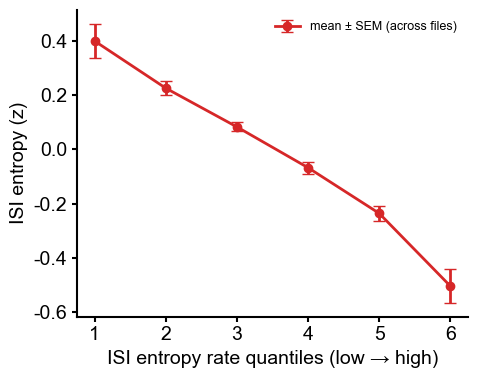

In [7]:
import os, pickle
import numpy as np
import pandas as pd
from scipy.stats import sem
import os
import glob
import pickle
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import sem as scipy_sem # Use a named import to avoid confusion
from scipy.stats import linregress

import numpy as np
from scipy.stats import gaussian_kde
import matplotlib as mpl

import matplotlib as mpl
def _force_sextiles(series, k=6):
    """
    Return Int64 tiles 1..k. Try qcut; if it yields <k bins, fall back to
    rank-based qcut that still returns k bins when N>=k. If N<k -> all NA.
    """
    s = pd.to_numeric(series, errors="coerce")
    s = s.replace([np.inf, -np.inf], np.nan)

    # 1) Try ordinary quantile sextiles
    try:
        t = pd.qcut(s, q=k, labels=False, duplicates="drop")
        if pd.Series(t).nunique(dropna=True) == k:
            return t.astype("Int64") + 1
    except Exception:
        pass

    # 2) Fallback: rank-based sextiles (equal-count by rank)
    rk = s.rank(method="first")
    if rk.notna().sum() >= k:
        t = pd.qcut(rk, q=k, labels=False)
        return t.astype("Int64") + 1

def load_pool_rate_binned_isi(pkl_dir, rate_col, state="NREM", n_bins=6, min_bins_required=3):
    pooled = []
    n_files_used = 0
    n_files_skipped = 0

    for file in os.listdir(pkl_dir):
        if not file.endswith(".pkl"):
            continue
        full_path = os.path.join(pkl_dir, file)
        try:
            with open(full_path, "rb") as f:
                data = pickle.load(f)

            df = data.get("per_center", None)
            print(df)

            if df is None or len(df) == 0:
                n_files_skipped += 1; continue

            df = df[df["state"] == state].copy()
            need = ["isi_entropy", rate_col]
            if df.empty or not set(need).issubset(df.columns):
                n_files_skipped += 1; continue

            df = df[need].replace([np.inf, -np.inf], np.nan).dropna()
            if df.empty:
                n_files_skipped += 1; continue

            # per-file z of d2
            d2_std = df["isi_entropy"].std(ddof=0)
            if not np.isfinite(d2_std) or d2_std == 0:
                n_files_skipped += 1; continue
            df["isi_entropy_norm"] = (df["isi_entropy"] - df["isi_entropy"].mean()) / d2_std

            # ---- FORCE 6 TILES (fallback to rank if qcut collapses) ----
            tiles = _force_sextiles(df[rate_col], k=n_bins)
            df["tile"] = tiles
            n_uniq = df["tile"].nunique(dropna=True)
            if n_uniq < min_bins_required:
                # not enough valid bins (e.g., <6 rows); skip file
                n_files_skipped += 1; continue

            df["file_id"] = os.path.splitext(file)[0]
            df["state"] = state
            df["rate_col"] = rate_col

            pooled.append(df[["file_id","state","rate_col","isi_entropy_norm",rate_col,"tile"]])
            n_files_used += 1

        except Exception:
            n_files_skipped += 1
            print(f"Skipping {file}: Missing columns. Available columns: {df.columns}")
            continue

    if not pooled:
        raise ValueError("No usable data loaded after per-file binning.")

    pooled_df = pd.concat(pooled, ignore_index=True)
    print(f"✅ Used {n_files_used} files; skipped {n_files_skipped}.")
    print(pooled_df.groupby("tile")["isi_entropy_norm"].count().rename("count_by_tile"))
    return pooled_df
def plot_isi_by_rate_tile_pooled_crossfileSEM(pooled_df, n_bins=6, title=None, color="tab:blue", save_path=None):
    """
    Plot mean z(D²) per tile with SEM computed ACROSS FILES.
    Steps:
      1) per-file, per-tile mean of d2_norm
      2) across-file mean and SEM of those per-file means
    """
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from scipy.stats import linregress

    # keep only 1..n_bins
    d = pooled_df.copy()
    d = d[d["tile"].between(1, n_bins)]

    # --- (1) per-file mean within each tile
    pf = (d.groupby(["file_id","tile"], observed=True)["isi_entropy_norm"]
            .mean()
            .rename("pf_mean")
            .reset_index())

    # --- (2) across-file mean & SEM per tile
    tile_mean = pf.groupby("tile")["pf_mean"].mean()
    tile_sem  = pf.groupby("tile")["pf_mean"].apply(lambda x: x.std(ddof=1) / np.sqrt(x.count()))
    n_files_per_tile = pf.groupby("tile")["file_id"].nunique()

    # ensure we have an entry for every 1..n_bins
    idx = pd.Index(range(1, n_bins+1), name="tile")
    tile_mean = tile_mean.reindex(idx)
    tile_sem  = tile_sem.reindex(idx)
    n_files_per_tile = n_files_per_tile.reindex(idx).fillna(0).astype(int)

    xs = tile_mean.index.to_numpy(int)
    ys = tile_mean.values
    es = tile_sem.values

    # linear trend on cross-file means
    ok = np.isfinite(ys)
    if ok.sum() >= 2:
        lr = linregress(xs[ok], ys[ok])
        r2 = lr.rvalue**2
        p  = lr.pvalue
        rvalue=lr.rvalue
        p_str = ("p < 1e-45" if p < 1e-45 else (f"p = {p:.2e}" if p < 0.001 else f"p = {p:.3f}"))
    else:
        r2, p_str = np.nan, "p = NA"

    print("\n📊 Linear trend on cross-file means:")
    print(f"  R² = {r2:.3f}, {p_str}")
    print(f"  r = {rvalue:.3f}")
    print("  files per tile:", dict(zip(xs, n_files_per_tile.tolist())))

    plt.figure(figsize=(5,4))
    plt.errorbar(xs, ys, yerr=es, fmt='-o', capsize=4, color=color, linewidth=2, label="mean ± SEM (across files)")

    # # optional OLS line for reference
    # if ok.sum() >= 2:
    #     yfit = lr.intercept + lr.slope * xs
    #     plt.plot(xs, yfit, linestyle="--", linewidth=1.5, color=color, alpha=0.6, label="OLS on cross-file means")

    plt.xticks(xs)
    plt.xlabel(title or "Rate tiles (low → high)")
    plt.ylabel("ISI entropy (z)")
    try:
        import seaborn as sns
        sns.despine()
    except Exception:
        pass
    ax = plt.gca()
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.legend(frameon=False, fontsize=9)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=300)
        print(f"Figure saved to {save_path}")
    plt.show()
pkl_dir=r"D:\Documents\GitHub\Sleep_criticaltiy\data\rats"
df_ripple_pooled_isi = load_pool_rate_binned_isi(
    pkl_dir, rate_col="ripple_rate", state="NREM", n_bins=6
)
plot_isi_by_rate_tile_pooled_crossfileSEM(
    df_ripple_pooled_isi, n_bins=6,
    title="ISI entropy rate quantiles (low → high)",
    color="tab:red",
    save_path=r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\supplementary\individual_fig_supp\figS6_G_Rat_isi_entropy_by_d2_tile_pooled.svg"
)

FigS6_F_Barr_d2 

✅ Used 12 files; skipped 0.
tile
1    4655
2    4648
3    4653
4    4646
5    4649
6    4656
Name: count_by_tile, dtype: int64

📊 Linear trend on pooled-window mean (tile means):
  slope=-0.0417, R²=0.833, p = 0.011
  r = -0.913
  files per tile: {1: 12, 2: 12, 3: 12, 4: 12, 5: 12, 6: 12}
Figure saved to D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\supplementary\individual_fig_supp\figS6_F_barrage_rate_by_d2_tile_pooled.svg


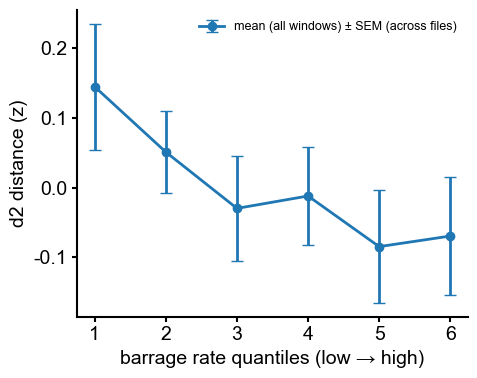

In [10]:
import os, pickle
import numpy as np
import pandas as pd
from scipy.stats import sem
import os
import glob
import pickle
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import sem as scipy_sem # Use a named import to avoid confusion
from scipy.stats import linregress

import numpy as np
from scipy.stats import gaussian_kde
import matplotlib as mpl

import matplotlib as mpl

# Global font: prefer Arial, with safe fallbacks
mpl.rcParams['svg.fonttype'] = 'none' 
mpl.rcParams['text.usetex'] = False
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = [
    'Helvetica Neue', 'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
]

# Mathtext to match
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Helvetica Neue'   # or 'Helvetica'
mpl.rcParams['mathtext.it'] = 'Helvetica Neue:italic'
mpl.rcParams['mathtext.bf'] = 'Helvetica Neue:bold'

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
def _force_sextiles(series, k=6):
    """
    Return Int64 tiles 1..k. Try qcut; if it yields <k bins, fall back to
    rank-based qcut that still returns k bins when N>=k. If N<k -> all NA.
    """
    s = pd.to_numeric(series, errors="coerce")
    s = s.replace([np.inf, -np.inf], np.nan)

    # 1) Try ordinary quantile sextiles
    try:
        t = pd.qcut(s, q=k, labels=False, duplicates="drop")
        if pd.Series(t).nunique(dropna=True) == k:
            return t.astype("Int64") + 1
    except Exception:
        pass

    # 2) Fallback: rank-based sextiles (equal-count by rank)
    rk = s.rank(method="first")
    if rk.notna().sum() >= k:
        t = pd.qcut(rk, q=k, labels=False)
        return t.astype("Int64") + 1

    # 3) Not enough rows to form k bins
    return pd.Series(pd.NA, index=s.index, dtype="Int64")
import pandas as pd
import numpy as np

def _force_equal_width(series, k=6):
    """
    Return Int64 bins 1..k based on equal-width intervals.
    Uses pd.cut (min to max divided into k segments).
    If valid data is insufficient (empty), returns all NA.
    """
    # 1) Clean data
    s = pd.to_numeric(series, errors="coerce")
    s = s.replace([np.inf, -np.inf], np.nan)
    
    # Check if we have enough data to define a range (at least 1 valid point)
    if s.notna().sum() == 0:
        return pd.Series(pd.NA, index=s.index, dtype="Int64")

    # 2) Apply Equal-Width Binning
    try:
        # pd.cut splits the range (min, max) into k linear intervals.
        # labels=False returns integer codes 0..(k-1).
        # include_lowest=True ensures the minimum value is included in the first bin.
        t = pd.cut(s, bins=k, labels=False, include_lowest=True)
        
        # Convert to 1..k Int64
        return t.astype("Int64") + 1
        
    except Exception:
        # Fallback for edge cases (e.g. constant value where min == max)
        return pd.Series(pd.NA, index=s.index, dtype="Int64")
def load_pool_rate_binned(pkl_dir, rate_col, state="NREM", n_bins=6, min_bins_required=2):
    pooled = []
    n_files_used = 0
    n_files_skipped = 0

    for file in os.listdir(pkl_dir):
        if not file.endswith(".pkl"):
            continue
        full_path = os.path.join(pkl_dir, file)
        try:
            with open(full_path, "rb") as f:
                data = pickle.load(f)

            df = data.get("per_center", None)
            if df is None or len(df) == 0:
                n_files_skipped += 1; continue

            df = df[df["state"] == state].copy()
            need = ["d2", rate_col]
            if df.empty or not set(need).issubset(df.columns):
                n_files_skipped += 1; continue

            df = df[need].replace([np.inf, -np.inf], np.nan).dropna()
            if df.empty:
                n_files_skipped += 1; continue

            # per-file z of d2
            d2_std = df["d2"].std(ddof=0)
            if not np.isfinite(d2_std) or d2_std == 0:
                n_files_skipped += 1; continue
            df["d2_norm"] = (df["d2"] - df["d2"].mean()) / d2_std

            # ---- FORCE 6 TILES (fallback to rank if qcut collapses) ----
            tiles = _force_sextiles(df[rate_col], k=n_bins)
            df["tile"] = tiles
            n_uniq = df["tile"].nunique(dropna=True)
            if n_uniq < min_bins_required:
                # not enough valid bins (e.g., <6 rows); skip file
                n_files_skipped += 1; continue

            df["file_id"] = os.path.splitext(file)[0]
            df["state"] = state
            df["rate_col"] = rate_col

            pooled.append(df[["file_id","state","rate_col","d2_norm",rate_col,"tile"]])
            n_files_used += 1

        except Exception:
            n_files_skipped += 1
            continue

    if not pooled:
        raise ValueError("No usable data loaded after per-file binning.")

    pooled_df = pd.concat(pooled, ignore_index=True)
    print(f"✅ Used {n_files_used} files; skipped {n_files_skipped}.")
    print(pooled_df.groupby("tile")["d2_norm"].count().rename("count_by_tile"))
    return pooled_df

import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import linregress

def plot_d2_by_rate_tile_pooled(pooled_df, n_bins=6, title=None, color="tab:blue",save_path=None):
    # Keep only tiles within 1..n_bins (some files may have fewer bins)
    df = pooled_df.copy()
    df = df[df["tile"].between(1, n_bins)]

    # aggregate across files within each tile
    grp = df.groupby("tile")["d2_norm"]
    means = grp.mean()
    errs  = grp.apply(sem)
    counts = grp.size()

    # linear trend on aggregated means (tile index 1..n_bins)
    xs = means.index.astype(int).values
    lr = linregress(xs, means.values)
    r2 = lr.rvalue ** 2
    p = lr.pvalue

    # pretty p
    if p == 0:
        p_str = "p < 1×10⁻⁴⁵"
    else:
        exp = int(np.floor(np.log10(p)))
        mant = p / (10 ** exp)
        p_str = f"p = {mant:.1f} × 10^{exp}"

    print(f"\n📊 Linear trend on pooled means:")
    print(f"  R² = {r2:.3f}, {p_str}")
    print("  counts per tile:\n", counts.to_string())

    # plot
    plt.figure(figsize=(5,4))
    plt.errorbar(xs, means.values, yerr=errs.values, fmt='-o', capsize=4, color=color, linewidth=2)
    plt.xticks(xs)
    ylab = df["rate_col"].iloc[0].replace("_rate_hz", " rate (Hz)").replace("_"," ").capitalize()
    plt.xlabel(title)
    plt.ylabel("d2 distance (z)")
    sns.despine()
    ax = plt.gca()
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.tight_layout()
    # plt.savefig(save_path, dpi=300)
    plt.show()
# Barrage: per-file quantile binning, then pool
pkl_dir=r"D:\Documents\GitHub\Sleep_criticaltiy\data\rats\ripple_barr\isi"
df_barrage_pooled = load_pool_rate_binned(
    pkl_dir, rate_col="barrage_rate", state="NREM", n_bins=6
)
def plot_d2_by_rate_tile_mean_allwindows_sem_acrossfiles(pooled_df, n_bins=6, title=None,
                                                        color="tab:blue", save_path=None):
    """
    Mean per tile: pooled across ALL windows (each window contributes equally).
    SEM per tile: across FILES (based on per-file means), so error bars reflect between-session variability.

    Requires columns: ["tile", "file_id", "d2_norm"].
    """
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from scipy.stats import linregress

    d = pooled_df.copy()
    d = d[d["tile"].between(1, n_bins)].dropna(subset=["tile", "file_id", "d2_norm"])

    # --- MEAN across ALL windows (pooled) ---
    mean_all = d.groupby("tile", observed=True)["d2_norm"].mean()

    # --- SEM across FILES: compute per-file mean within each tile, then SEM across those means ---
    pf = (d.groupby(["file_id", "tile"], observed=True)["d2_norm"]
            .mean()
            .rename("pf_mean")
            .reset_index())

    sem_across_files = pf.groupby("tile")["pf_mean"].apply(lambda x: x.std(ddof=1) / np.sqrt(x.count()))
    n_files_per_tile = pf.groupby("tile")["file_id"].nunique()

    # ensure full 1..n_bins index
    idx = pd.Index(range(1, n_bins + 1), name="tile")
    mean_all = mean_all.reindex(idx)
    sem_across_files = sem_across_files.reindex(idx)
    n_files_per_tile = n_files_per_tile.reindex(idx).fillna(0).astype(int)

    xs = idx.to_numpy(int)
    ys = mean_all.to_numpy(float)
    es = sem_across_files.to_numpy(float)

    # optional: linear trend on the mean curve (tile means)
    ok = np.isfinite(ys)
    if ok.sum() >= 2:
        lr = linregress(xs[ok], ys[ok])
        r2 = lr.rvalue**2
        p = lr.pvalue
        rvalue=lr.rvalue
        p_str = ("p < 1e-45" if p < 1e-45 else (f"p = {p:.2e}" if p < 0.001 else f"p = {p:.3f}"))
        print("\n📊 Linear trend on pooled-window mean (tile means):")
        print(f"  slope={lr.slope:.4f}, R²={r2:.3f}, {p_str}")
        print(f"  r = {rvalue:.3f}")
    else:
        print("\n📊 Linear trend: not enough finite points.")

    print("  files per tile:", dict(zip(xs, n_files_per_tile.tolist())))

    # plot
    plt.figure(figsize=(5, 4))
    plt.errorbar(xs, ys, yerr=es, fmt='-o', capsize=4, color=color,
                 linewidth=2, label="mean (all windows) ± SEM (across files)")

    plt.xticks(xs)
    plt.xlabel(title or "Rate tiles (low → high)")
    plt.ylabel("d2 distance (z)")

    try:
        import seaborn as sns
        sns.despine()
    except Exception:
        pass

    ax = plt.gca()
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.legend(frameon=False, fontsize=9)
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"Figure saved to {save_path}")

    plt.show()

plot_d2_by_rate_tile_mean_allwindows_sem_acrossfiles(
    df_barrage_pooled, n_bins=6,
    title="barrage rate quantiles (low → high)",
    color="tab:blue",
    save_path=r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\supplementary\individual_fig_supp\figS6_F_barrage_rate_by_d2_tile_pooled.svg"
)

FigS6_G

✅ Used 12 files; skipped 0.
tile
1    4655
2    4647
3    4653
4    4645
5    4648
6    4656
Name: count_by_tile, dtype: int64

📊 Linear trend on pooled means:
  R² = 0.829, p = 1.2 × 10^-2
  counts per tile:
 tile
1    4655
2    4647
3    4653
4    4645
5    4648
6    4656


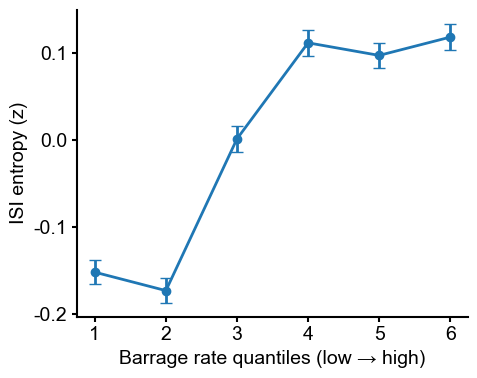


📊 Linear trend on pooled-window mean (tile means):
  slope=0.0649, R²=0.829, r=0.911, p = 0.012
  files per tile: {1: 12, 2: 12, 3: 12, 4: 12, 5: 12, 6: 12}
Figure saved to D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\supplementary\individual_fig_supp\figS6_G_barrage_rate_by_isi_tile_pooled.svg


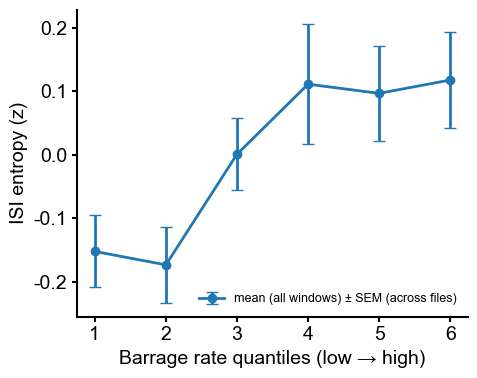

In [ ]:
import os, pickle
def load_pool_rate_binned_isi(pkl_dir, rate_col, state="NREM", n_bins=6, min_bins_required=3):
    pooled = []
    n_files_used = 0
    n_files_skipped = 0

    for file in os.listdir(pkl_dir):
        if not file.endswith(".pkl"):
            continue
        full_path = os.path.join(pkl_dir, file)
        try:
            with open(full_path, "rb") as f:
                data = pickle.load(f)

            df = data.get("per_center", None)
            if df is None or len(df) == 0:
                n_files_skipped += 1; continue

            df = df[df["state"] == state].copy()
            need = ["isi_entropy", rate_col]
            if df.empty or not set(need).issubset(df.columns):
                n_files_skipped += 1; continue

            df = df[need].replace([np.inf, -np.inf], np.nan).dropna()
            if df.empty:
                n_files_skipped += 1; continue

            # per-file z of d2
            d2_std = df["isi_entropy"].std(ddof=0)
            if not np.isfinite(d2_std) or d2_std == 0:
                n_files_skipped += 1; continue
            df["isi_entropy_norm"] = (df["isi_entropy"] - df["isi_entropy"].mean()) / d2_std

            # ---- FORCE 6 TILES (fallback to rank if qcut collapses) ----
            tiles = _force_sextiles(df[rate_col], k=n_bins)
            df["tile"] = tiles
            n_uniq = df["tile"].nunique(dropna=True)
            if n_uniq < min_bins_required:
                # not enough valid bins (e.g., <6 rows); skip file
                n_files_skipped += 1; continue

            df["file_id"] = os.path.splitext(file)[0]
            df["state"] = state
            df["rate_col"] = rate_col

            pooled.append(df[["file_id","state","rate_col","isi_entropy_norm",rate_col,"tile"]])
            n_files_used += 1

        except Exception:
            n_files_skipped += 1
            continue

    if not pooled:
        raise ValueError("No usable data loaded after per-file binning.")

    pooled_df = pd.concat(pooled, ignore_index=True)
    print(f"✅ Used {n_files_used} files; skipped {n_files_skipped}.")
    print(pooled_df.groupby("tile")["isi_entropy_norm"].count().rename("count_by_tile"))
    return pooled_df
def plot_isi_by_rate_tile_pooled(pooled_df, n_bins=6, title=None, color="tab:blue",save_path=None):
    # Keep only tiles within 1..n_bins (some files may have fewer bins)
    df = pooled_df.copy()
    df = df[df["tile"].between(1, n_bins)]

    # aggregate across files within each tile
    grp = df.groupby("tile")["isi_entropy_norm"]
    means = grp.mean()
    errs  = grp.apply(sem)
    counts = grp.size()

    # linear trend on aggregated means (tile index 1..n_bins)
    xs = means.index.astype(int).values
    lr = linregress(xs, means.values)
    r2 = lr.rvalue ** 2
    p = lr.pvalue

    # pretty p
    if p == 0:
        p_str = "p < 1×10⁻⁴⁵"
    else:
        exp = int(np.floor(np.log10(p)))
        mant = p / (10 ** exp)
        p_str = f"p = {mant:.1f} × 10^{exp}"

    print(f"\n📊 Linear trend on pooled means:")
    print(f"  R² = {r2:.3f}, {p_str}")
    print("  counts per tile:\n", counts.to_string())

    # plot
    plt.figure(figsize=(5,4))
    plt.errorbar(xs, means.values, yerr=errs.values, fmt='-o', capsize=4, color=color, linewidth=2)
    plt.xticks(xs)
    ylab = df["rate_col"].iloc[0].replace("_rate_hz", " rate (Hz)").replace("_"," ").capitalize()
    plt.xlabel(title)
    plt.ylabel("ISI entropy (z)")
    sns.despine()
    ax = plt.gca()
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.tight_layout()
    # plt.savefig(save_path, dpi=300)
    plt.show()
def plot_isi_by_rate_tile_mean_allwindows_sem_acrossfiles(pooled_df, n_bins=6, title=None,
                                                        color="tab:blue", save_path=None):
    """
    Mean per tile: pooled across ALL windows (each window contributes equally).
    SEM per tile: across FILES (based on per-file means), so error bars reflect between-session variability.

    Requires columns: ["tile", "file_id", "d2_norm"].
    """
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    from scipy.stats import linregress

    d = pooled_df.copy()
    d = d[d["tile"].between(1, n_bins)].dropna(subset=["tile", "file_id", "isi_entropy_norm"])

    # --- MEAN across ALL windows (pooled) ---
    mean_all = d.groupby("tile", observed=True)["isi_entropy_norm"].mean()

    # --- SEM across FILES: compute per-file mean within each tile, then SEM across those means ---
    pf = (d.groupby(["file_id", "tile"], observed=True)["isi_entropy_norm"]
            .mean()
            .rename("pf_mean")
            .reset_index())

    sem_across_files = pf.groupby("tile")["pf_mean"].apply(lambda x: x.std(ddof=1) / np.sqrt(x.count()))
    n_files_per_tile = pf.groupby("tile")["file_id"].nunique()

    # ensure full 1..n_bins index
    idx = pd.Index(range(1, n_bins + 1), name="tile")
    mean_all = mean_all.reindex(idx)
    sem_across_files = sem_across_files.reindex(idx)
    n_files_per_tile = n_files_per_tile.reindex(idx).fillna(0).astype(int)

    xs = idx.to_numpy(int)
    ys = mean_all.to_numpy(float)
    es = sem_across_files.to_numpy(float)

    # optional: linear trend on the mean curve (tile means)
    ok = np.isfinite(ys)
    if ok.sum() >= 2:
        lr = linregress(xs[ok], ys[ok])
        r2 = lr.rvalue**2
        p = lr.pvalue
        r=lr.rvalue
        p_str = ("p < 1e-45" if p < 1e-45 else (f"p = {p:.2e}" if p < 0.001 else f"p = {p:.3f}"))
        print("\n📊 Linear trend on pooled-window mean (tile means):")
        print(f"  slope={lr.slope:.4f}, R²={r2:.3f}, r={r:.3f}, {p_str}")
    else:
        print("\n📊 Linear trend: not enough finite points.")

    print("  files per tile:", dict(zip(xs, n_files_per_tile.tolist())))

    # plot
    plt.figure(figsize=(5, 4))
    plt.errorbar(xs, ys, yerr=es, fmt='-o', capsize=4, color=color,
                 linewidth=2, label="mean (all windows) ± SEM (across files)")

    plt.xticks(xs)
    plt.xlabel(title or "Rate tiles (low → high)")
    plt.ylabel("ISI entropy (z)")

    try:
        import seaborn as sns
        sns.despine()
    except Exception:
        pass

    ax = plt.gca()
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.legend(frameon=False, fontsize=9)
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"Figure saved to {save_path}")

    plt.show()

pkl_dir=r"D:\Documents\GitHub\Sleep_criticaltiy\data\rats\ripple_barr\isi"
df_barrage_pooled_isi = load_pool_rate_binned_isi(
    pkl_dir, rate_col="barrage_rate", state="NREM", n_bins=6
)
plot_isi_by_rate_tile_mean_allwindows_sem_acrossfiles(
    df_barrage_pooled_isi, n_bins=6,
    title="Barrage rate quantiles (low → high)",
    color="tab:blue",
    save_path=r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\supplementary\individual_fig_supp\figS6_G_barrage_rate_by_isi_tile_pooled.svg"

)

Fig1 H and I

In [3]:
import numpy as np
import pandas as pd
from pathlib import Path
import os, re, glob, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import matplotlib.pyplot as plt
import nelpy as nel
import nelpy.plotting as npl
import numpy as np
import seaborn as sns
from neuro_py.io import loading
from neuro_py.plotting.figure_helpers import set_size
from neuro_py.tuning import maps
from skimage import measure
import os
import pandas as pd
import scipy.io as sio

# ---------- Summary stats ----------

# ---------- 1) Load all pickles ----------
FOLDER = r"D:\Documents\GitHub\Sleep_criticaltiy\data\rats\cross_state\pairs"
files = sorted(glob.glob(os.path.join(FOLDER, "*_d2_mua_pairs.pkl")))
assert files, f"No pairs .pkl files in {FOLDER}"

dfs = []
for f in files:
    try:
        df = pd.read_pickle(f)
        # ensure keys exist; infer from filename if needed
        if "animal" not in df.columns or "day" not in df.columns or "region" not in df.columns:
            base = os.path.basename(f)
            m = re.match(r"([^_]+)_day([^_]+)_([^_]+)_d2_mua_pairs\.pkl", base)
            if m:
                df["animal"] = df.get("animal", m.group(1))
                df["day"]    = df.get("day",    m.group(2))
                df["region"] = df.get("region", m.group(3))
            else:
                df["animal"] = df.get("animal", "NA")
                df["day"]    = df.get("day", "NA")
                df["region"] = df.get("region", "NA")
        if "animal_day" not in df.columns:
            df["animal_day"] = df["animal"].astype(str) + "_" + df["day"].astype(str)
        dfs.append(df)
    except Exception as e:
        print(f"⚠️ Skipping {os.path.basename(f)}: {e}")

all_pairs = pd.concat(dfs, ignore_index=True)
all_pairs["group"] = all_pairs["group"].astype(str)

paths = [
r"V:\data\hpc_ctx_project\HP17\hp17_day2_20250413",
r"V:\data\hpc_ctx_project\HP17\hp17_day23_20250507",
r"V:\data\hpc_ctx_project\HP17\hp17_day26_20250510",
r"V:\data\hpc_ctx_project\HP17\hp17_day32_20250516",
r"V:\data\hpc_ctx_project\HP17\hp17_day34_20250518",
r"V:\data\hpc_ctx_project\HP17\hp17_day36_20250520",
r"V:\data\hpc_ctx_project\HP17\hp17_day40_20250526",
r"V:\data\hpc_ctx_project\HP15\hp15_day35_20250205",
r"V:\data\hpc_ctx_project\HP18\hp18_day13_20250417",
r"V:\data\hpc_ctx_project\HP18\hp18_day16_20250420",
r"V:\data\hpc_ctx_project\HP18\hp18_day17_20250421",
r"V:\data\hpc_ctx_project\HP18\hp18_day36_20250510",
r"V:\data\hpc_ctx_project\HP18\hp18_day40_20250514",
r"V:\data\hpc_ctx_project\HP18\hp18_day48_20250522",
r"V:\data\hpc_ctx_project\HP18\hp18_day49_20250523",
r"V:\data\hpc_ctx_project\HP18\hp18_day55_20250529",
r"S:\data\latentseq\RM10\rm10_day6_20250810",
r"S:\data\latentseq\RM10\rm10_day10_20250814",
r"S:\data\latentseq\RM10\rm10_day11_20250815",
r"S:\data\latentseq\RM10\rm10_day12_20250817",
r"U:\data\HMC\HMC1\day8",
r"U:\data\HMC\HMC1\day9",
r"U:\data\HMC\HMC1\day10",
r"U:\data\HMC\HMC1\day11",
]
# ----------------------------
# paths → lookup
# ----------------------------
import numpy as np
import pandas as pd
from pathlib import Path
from pathlib import Path
import re



def session_key(p):
    """
    Normalizes strings like:
    'RM10_rm10_day6_20250810' -> 'rm10_day6'
    'V:\\...\\HP15\\hp15_day31_20250130' -> 'hp15_day31'
    """
    name = Path(p).name.lower()

    # Case 1: .../<animal>/day10
    if re.fullmatch(r"day\d+", name):
        animal = Path(p).parent.name.lower()
        return f"{animal}_{name}"

    # Case 2: Extract animal and day from complex strings
    # This looks for the first occurrence of an animal ID followed by 'day' and digits
    m = re.search(r"(?P<animal>[a-z0-9]+)_.*?day(?P<day_num>\d+)", name)
    if m:
        return f"{m.group('animal')}_day{m.group('day_num')}"

    return name
path_map = {session_key(p): Path(p) for p in paths}
all_pairs = all_pairs.copy()
all_pairs["epoch_name"]  = np.nan
all_pairs["environment"] = np.nan

keep = np.ones(len(all_pairs), dtype=bool)

# 2. Process the dataframe
for raw_key, idx_sub in all_pairs.groupby("animal_day").groups.items():
    # Clean the dataframe key so it matches the path_map keys
    clean_key = session_key(str(raw_key)) 
    
    basepath = path_map.get(clean_key)
    
    if basepath is None:
        print(f"Missing basepath for raw: '{raw_key}' (cleaned: '{clean_key}')")
        continue

    print(f"Processing {clean_key} at {basepath}")
    epoch_df = loading.load_epoch(str(basepath))

    name = epoch_df["name"].astype(str).str.lower()
    env  = epoch_df.get("environment", pd.Series("", index=epoch_df.index)).astype(str)

    # ----------------------------
    # (A) Annotate environment + epoch_name for ALL rows
    # ----------------------------
    times_all = all_pairs.loc[idx_sub, "time"].to_numpy(float)

    for _, row in epoch_df.iterrows():
        t0 = float(row["startTime"])
        t1 = float(row["stopTime"])

        in_epoch = (times_all >= t0) & (times_all <= t1)
        if not in_epoch.any():
            continue

        # annotate environment (always)
        all_pairs.loc[idx_sub[in_epoch], "environment"] = row.get("environment")

        # annotate epoch_name if present
        if "name" in row and pd.notna(row["name"]):
            all_pairs.loc[idx_sub[in_epoch], "epoch_name"] = row["name"]

    # ----------------------------
    # Identify TASK epochs
    # ----------------------------
    is_sleep = env.astype(str).str.lower().str.contains("sleep") | name.str.contains("sleep")

    is_tmaze = (
        env.astype(str).str.lower().str.contains("cheeseboard")
        | env.astype(str).str.lower().str.contains("linear")
        | env.astype(str).str.lower().str.contains("t-maze")
        | env.astype(str).str.lower().str.contains("task")
        | name.str.contains("maze")
        | name.str.contains("cheeseboard")
        | name.str.contains("t-maze")
        | name.str.startswith("freet")
        | name.str.startswith("t_")
    )

    task_epochs = epoch_df[is_tmaze & ~is_sleep].copy()

    # ----------------------------
    # (B) KEEP ONLY wake points that are IN task epochs
    # ----------------------------
    wake_idx = idx_sub[
        all_pairs.loc[idx_sub, "group"]
        .isin(["Wake θ", "Wake non-θ"])
        .to_numpy()
    ]

    if task_epochs.empty:
        # no task epochs => drop all wake points
        keep[wake_idx] = False
    else:
        times_wake = all_pairs.loc[wake_idx, "time"].to_numpy(float)

        in_any_task = np.zeros(times_wake.shape[0], dtype=bool)
        for _, row in task_epochs.iterrows():
            t0 = float(row["startTime"])
            t1 = float(row["stopTime"])
            in_any_task |= (times_wake >= t0) & (times_wake <= t1)

        # drop wake points NOT in task
        keep[wake_idx[~in_any_task]] = False

    # ----------------------------
    # (C) If manipulation non-empty → remove NREM / REM
    # ----------------------------
    if "manipulation" in epoch_df.columns:
        manip = epoch_df["manipulation"].astype(str).str.lower().str.strip()
        sil_epochs = epoch_df[manip == "pfc_silence"]

        if not sil_epochs.empty:
            # only drop NREM/REM points that fall inside pfc_silence epochs
            times_all = all_pairs.loc[idx_sub, "time"].to_numpy(float)
            is_sleep_row = all_pairs.loc[idx_sub, "group"].isin(["NREM", "REM"]).to_numpy()

            in_sil = np.zeros(times_all.shape[0], dtype=bool)
            for _, row in sil_epochs.iterrows():
                t0 = float(row["startTime"])
                t1 = float(row["stopTime"])
                in_sil |= (times_all >= t0) & (times_all <= t1)

            # drop = (sleep row) AND (time inside pfc_silence epoch)
            to_drop = is_sleep_row & in_sil
            keep[idx_sub[to_drop]] = False

# ----------------------------
# Final cleaned dataframe
# ----------------------------
all_pairs_clean = all_pairs.loc[keep].copy()



Processing hmc1_day10 at U:\data\HMC\HMC1\day10
Processing hmc1_day11 at U:\data\HMC\HMC1\day11
Processing hmc1_day8 at U:\data\HMC\HMC1\day8


C:\Users\Cornell\AppData\Local\Temp\ipykernel_32248\1594986814.py:147: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'sleep' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
C:\Users\Cornell\AppData\Local\Temp\ipykernel_32248\1594986814.py:151: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'preSleep_210413_065510' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.


Processing hmc1_day9 at U:\data\HMC\HMC1\day9
Processing hp15_day35 at V:\data\hpc_ctx_project\HP15\hp15_day35_20250205
Processing hp17_day23 at V:\data\hpc_ctx_project\HP17\hp17_day23_20250507
Processing hp17_day26 at V:\data\hpc_ctx_project\HP17\hp17_day26_20250510
Processing hp17_day2 at V:\data\hpc_ctx_project\HP17\hp17_day2_20250413
Processing hp17_day32 at V:\data\hpc_ctx_project\HP17\hp17_day32_20250516
Processing hp17_day34 at V:\data\hpc_ctx_project\HP17\hp17_day34_20250518
Processing hp17_day36 at V:\data\hpc_ctx_project\HP17\hp17_day36_20250520
Processing hp17_day40 at V:\data\hpc_ctx_project\HP17\hp17_day40_20250526
Missing basepath for raw: 'HP17_hp17_day49_20250604' (cleaned: 'hp17_day49')
Processing hp18_day13 at V:\data\hpc_ctx_project\HP18\hp18_day13_20250417
Processing hp18_day16 at V:\data\hpc_ctx_project\HP18\hp18_day16_20250420
Processing hp18_day17 at V:\data\hpc_ctx_project\HP18\hp18_day17_20250421
Processing hp18_day36 at V:\data\hpc_ctx_project\HP18\hp18_day36_

FigS5_C

Wake non-θ: n=6,916, r=-0.4133, p=1.268e-283, slope=-0.4310
Wake θ: n=6,689, r=0.1254, p=7.359e-25, slope=0.1274
NREM: n=73,572, r=0.1130, p=1.585e-207, slope=0.1115
REM: n=1,092, r=-0.3243, p=3.653e-28, slope=-0.2092


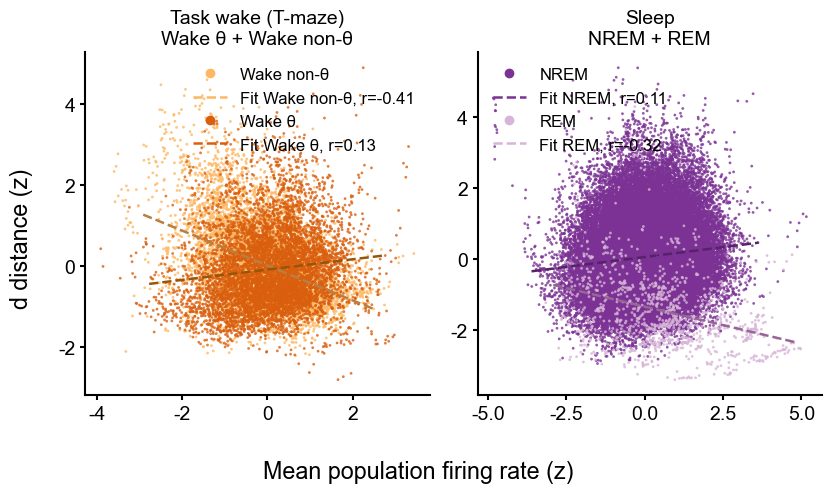

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
from matplotlib.lines import Line2D
from scipy import stats
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# 1) Collapse to Wake vs Sleep
# -----------------------------
wake_set  = {"Wake θ","Wake non-θ","Wake","WAKE"}
sleep_set = {"NREM","REM","REM4","Sleep","SLEEP"}

all_pairs = all_pairs_clean.copy()
all_pairs["group2"] = all_pairs["group"].map(
    lambda g: "Wake" if g in wake_set else ("Sleep" if g in sleep_set else np.nan)
)
pairs_ws = all_pairs.dropna(subset=["group2"]).copy()

# -----------------------------
# 2) z-score within (animal_day, group2)
# -----------------------------
def zscore_within(df, by=("animal_day", "group2")):
    out = df.copy()

    def safe_z(s):
        s = s.astype(float)
        sd = s.std(ddof=0)
        if (not np.isfinite(sd)) or sd == 0:
            return pd.Series(np.nan, index=s.index)
        return (s - s.mean()) / sd

    out["d2_z"]    = out.groupby(list(by), dropna=False)["d2"].transform(safe_z)
    out["mua30_z"] = out.groupby(list(by), dropna=False)["mua30"].transform(safe_z)
    return out

z_pairs = zscore_within(pairs_ws, by=("animal_day", "group2"))
MIN_N = 150

df = z_pairs.copy()

# keep only (animal_day, group) with >= 50 points
counts = df.groupby(["animal_day", "group"]).size()
keep_keys = counts[counts >= MIN_N].index

z_pairs = df.set_index(["animal_day", "group"]).loc[keep_keys].reset_index()
# --------------------------------
# 3) Define task wake & sleep sets
# --------------------------------

# --- Task wake: epochs with a T-maze label & wake θ / non-θ ---
task_wake_mask = (
    z_pairs["epoch_name"].notna() &
    z_pairs["group"].isin(["Wake θ", "Wake non-θ"])
)
task_wake = z_pairs[task_wake_mask].copy()

# --- Sleep: NREM vs REM/REM4 ---
def map_sleep(g):
    if g in {"NREM"}:
        return "NREM"
    if g in {"REM", "REM4"}:
        return "REM"
    return np.nan

z_pairs["sleep_substate"] = z_pairs["group"].map(map_sleep)
sleep_mask = z_pairs["sleep_substate"].notna()
sleep_pairs = z_pairs[sleep_mask].copy()
# --------------------------------
# 5) Helper: add regression line
# --------------------------------
def add_fit_line(ax, x, y, x_min, x_max, *, color='k', linestyle='--', lw=1.6):
    ok = np.isfinite(x) & np.isfinite(y)
    if ok.sum() < 3:
        return None, np.nan, np.nan
    lr = stats.linregress(x[ok], y[ok])
    xs = np.linspace(x_min, x_max, 200)
    ax.plot(xs, lr.slope * xs + lr.intercept,
            color=color, linestyle=linestyle, linewidth=lw)
    r, p = stats.pearsonr(x[ok], y[ok])
    return lr, r, p

# --------------------------------
# 6) Palettes
# --------------------------------
colors = {
    "NREM": "#56236a",
    "REM": "#976695",
    "THETA": "#97550a",
    "nonTHETA": "#b87f44"

}
wake_palette  = {"Wake θ": "#d95f0e", "Wake non-θ": "#fdb863"}
sleep_palette = {"NREM": "#7b3294", "REM": "#d7b5d8"}
wake_inline_palette  = {"Wake θ": "#97550a", "Wake non-θ": "#b87f44"}
sleep_inline_palette = {"NREM": "#56236a", "REM": "#976695"}
fig, axes = plt.subplots(1, 2, figsize=(8.5, 5), sharex=False, sharey=False)

# --------------------------------
# LEFT: task wake (θ vs non-θ)
# --------------------------------
ax = axes[0]
legend_handles = []
def local_limits(x, pad_frac=0.1):
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    if x.size == 0:
        return -1, 1
    lo, hi = np.percentile(x, [1, 99])
    span = hi - lo if hi > lo else 1.0
    pad = pad_frac * span
    return float(lo - pad), float(hi + pad)

for st in ["Wake non-θ", "Wake θ"]:
    sub = task_wake[task_wake["group"] == st]
    if sub.empty:
        continue

    x = sub["mua30_z"].to_numpy(float)
    y = sub["d2_z"].to_numpy(float)

    # scatter points
    sc = ax.scatter(
        x, y,
        s=4, alpha=0.8,
        color=wake_palette[st],
        edgecolors="none",
        rasterized=True
    )
    sc.set_rasterized(True)
    x_min_state, x_max_state = local_limits(x)
    # fit line for THIS state only
    lr, r, p = add_fit_line(
        ax, x, y,
        x_min=x_min_state, x_max=x_max_state,
        color=wake_inline_palette[st], linestyle="--", lw=1.8
    )
    print(f"{st}: n={np.isfinite(x*y).sum():,}, r={r:.4f}, p={p:.3e}, "
          f"slope={lr.slope if lr else np.nan:.4f}")

    # legend entries: marker + line for this state
    legend_handles.append(
        Line2D([0], [0], marker="o", linestyle="None",
               color=wake_palette[st], label=st)
    )
    legend_handles.append(
        Line2D([0], [0], color=wake_palette[st], linestyle="--", lw=1.8,
               label=f"Fit {st}, r={r:.2f}")
    )

ax.set_title("Task wake (T-maze)\nWake θ + Wake non-θ")
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(handles=legend_handles, frameon=False, fontsize=12)

# --------------------------------
# RIGHT: sleep (NREM vs REM)
# --------------------------------
ax = axes[1]
legend_handles_sleep = []
pad_sleep={"NREM":0.3,"REM":0.05}
for st in ["NREM", "REM"]:
    sub = sleep_pairs[sleep_pairs["sleep_substate"] == st]
    if sub.empty:
        continue

    x = sub["mua30_z"].to_numpy(float)
    y = sub["d2_z"].to_numpy(float)
    x_min_state, x_max_state = local_limits(x,pad_frac=pad_sleep[st])
    # scatter points
    sc = ax.scatter(
        x, y,
        s=4, alpha=0.8,
        color=sleep_palette[st],
        edgecolors="none",
        rasterized=True
    )
    sc.set_rasterized(True)

    # fit line for THIS sleep substate only
    lr, r, p = add_fit_line(
        ax, x, y,
        x_min=x_min_state, x_max=x_max_state,
        color=sleep_inline_palette[st], linestyle="--", lw=1.8
    )
    print(f"{st}: n={np.isfinite(x*y).sum():,}, r={r:.4f}, p={p:.3e}, "
          f"slope={lr.slope if lr else np.nan:.4f}")

    # legend entries
    legend_handles_sleep.append(
        Line2D([0], [0], marker="o", linestyle="None",
               color=sleep_palette[st], label=st)
    )
    legend_handles_sleep.append(
        Line2D([0], [0], color=sleep_palette[st], linestyle="--", lw=1.8,
               label=f"Fit {st}, r={r:.2f}")
    )

ax.set_title("Sleep\nNREM + REM")
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.legend(handles=legend_handles_sleep, frameon=False, fontsize=12)


# shared labels
fig.supxlabel("Mean population firing rate (z)")  # MUA_z on x
fig.supylabel("d distance (z)")                           # d2_z on y

plt.tight_layout()
fig.savefig(r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\individual_fig_main\figS5_C_rat_NREM_REM_MUA.svg", format="svg", dpi=300, bbox_inches="tight")
plt.show()

FigS5_D

In [5]:
# assume all_pairs already has:
# - 'd2'
# - 'MUA'  (or rename from 'mua30' if needed)
# - 'group'         (NREM, REM, Wake θ, etc.)
# - 'epoch_name'    (NaN for non-task, string for T-maze epochs)
# - 'animal', 'day' (for per-file ID)
# --- Tile by d2_z per state (6 tiles) ---
# ---------- Summary stats ----------
import matplotlib as mpl
# Global font: prefer Arial, with safe fallbacks
mpl.rcParams['svg.fonttype'] = 'none' 
mpl.rcParams['text.usetex'] = False
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = [
    'Helvetica Neue', 'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
]

# Mathtext to match
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Helvetica Neue'   # or 'Helvetica'
mpl.rcParams['mathtext.it'] = 'Helvetica Neue:italic'
mpl.rcParams['mathtext.bf'] = 'Helvetica Neue:bold'

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
# -------- settings --------
N_BINS = 6
MIN_PER_BIN = 2
BASELINE_Q = 0.25
STATE_LIST = ["NREM", "WAKE"]

# ---------- utils ----------
def coerce_to_df(dfs):
    if isinstance(dfs, pd.DataFrame):
        df = dfs.copy()
        if "__file__" not in df.columns:
            df["__file__"] = "file1"
        return df
    if isinstance(dfs, dict):
        parts = []
        for name, d in dfs.items():
            if isinstance(d, pd.DataFrame):
                t = d.copy()
                t["__file__"] = str(name)
                parts.append(t)
        return pd.concat(parts, ignore_index=True)
    parts = []
    for i, d in enumerate(dfs, start=1):
        if isinstance(d, pd.DataFrame):
            t = d.copy()
            if "__file__" not in t.columns:
                t["__file__"] = f"file{i}"
            parts.append(t)
    return pd.concat(parts, ignore_index=True)

def plot_bars(dfB, ycol, xlabel, title):
    if dfB.empty:
        print(f"[warn] empty results for: {title}")
        return
    x = np.arange(len(dfB))
    plt.figure(figsize=(6.5,4))
    plt.bar(x, dfB[ycol].values)
    plt.xticks(x, [f"{v:.2g}" for v in dfB["d2_center"].values], rotation=45, ha="right")
    plt.ylabel(ycol)
    plt.xlabel(xlabel)
    plt.title(title)
    plt.tight_layout()
    plt.show()

# ---------- per-file d2 normalization ----------
def add_perfile_d2_normalized(df, method="percentile"):
    """
    Adds a normalized d2 column 'd2n' computed per file.
    method: 'percentile' (0..1), 'z', or 'minmax'
    """
    df = df.copy()
    def _percentile_col(g):
        x = g["d2"].to_numpy(float)
        # ranks in [0,1]
        order = np.argsort(x)
        ranks = np.empty_like(order, dtype=float)
        ranks[order] = np.arange(x.size, dtype=float)
        q = ranks / max(x.size - 1, 1)  # avoid div/0 for size=1
        g["d2n"] = q
        return g

    def _z_col(g):
        # clip to 1–99% to compute robust-ish mean/std
        lo, hi = g["d2"].quantile([0.01, 0.99])
        xc = g["d2"].clip(lo, hi)
        mu, sd = xc.mean(), xc.std(ddof=0)
        sd = sd if sd > 0 else np.nan
        g["d2n"] = (g["d2"] - mu) / sd
        return g

    def _minmax_col(g):
        lo, hi = g["d2"].min(), g["d2"].max()
        span = hi - lo
        g["d2n"] = (g["d2"] - lo) / (span if span > 0 else np.nan)
        return g

    if method == "percentile":
        df = df.groupby("__file__", group_keys=False).apply(_percentile_col)
    elif method == "z":
        df = df.groupby("__file__", group_keys=False).apply(_z_col)
    elif method == "minmax":
        df = df.groupby("__file__", group_keys=False).apply(_minmax_col)
    else:
        raise ValueError("method must be 'percentile', 'z', or 'minmax'")
    return df

def perfile_dyn_by_bin(dstate, method="percentile", bin_mode="equalwidth"):
    """
    Returns one row per (__file__, d2_bin) with per-file dynamic-range metric.
    
    method:
        'percentile', 'z', 'minmax'  -> how to normalize d2 per file into 'd2n'
    bin_mode:
        'equalwidth' -> fixed-width bins in normalized d2n
        'tile'       -> quantile / equal-count bins (forced tiles)
    """
    if dstate.empty:
        return pd.DataFrame(columns=["__file__", "d2_bin", "d2_center", "dyn", "n_in_bin"])

    # 1) normalize d2 per file
    dstate = add_perfile_d2_normalized(dstate, method=method)

    # keep only finite d2n
    dstate = dstate[np.isfinite(dstate["d2n"])].copy()
    if dstate.empty:
        return pd.DataFrame(columns=["__file__", "d2_bin", "d2_center", "dyn", "n_in_bin"])

    # 2) define bins
    if bin_mode == "equalwidth":
        if method in ("percentile", "minmax"):
            bins = np.linspace(0, 1, N_BINS+1)
            centers = (bins[:-1] + bins[1:]) / 2.0
        else:  # z
            zmin, zmax = dstate["d2n"].quantile([0.01, 0.99])
            if not np.isfinite(zmin) or not np.isfinite(zmax) or zmax <= zmin:
                return pd.DataFrame(columns=["__file__", "d2_bin", "d2_center", "dyn", "n_in_bin"])
            bins = np.linspace(zmin, zmax, N_BINS+1)
            centers = (bins[:-1] + bins[1:]) / 2.0

        dstate["d2_bin"] = pd.cut(
            dstate["d2n"], bins=bins, labels=False, include_lowest=True)
        # lookup centers by integer bin index
        center_lookup = {i: float(c) for i, c in enumerate(centers)}

    elif bin_mode == "tile":
        # forced tiles: equal-count quantile bins across all rows
        # labels are 0..k-1; duplicates="drop" may give < N_BINS if data are degenerate
        dstate["d2_bin"] = pd.qcut(
            dstate["d2n"],
            q=N_BINS,
            labels=False,
            duplicates="drop"
        )
        # compute center as the median d2n within each tile
        centers_ser = (
            dstate
            .groupby("d2_bin")["d2n"]
            .median()
            .dropna()
        )
        center_lookup = centers_ser.to_dict()
    else:
        raise ValueError("bin_mode must be 'equalwidth' or 'tile'")

    # 3) per-(file, bin) mean of raw MUA
    fb_mean = dstate.groupby(["__file__", "d2_bin"])["MUA"].transform("mean")

    # normalize: mean within each (file, bin) becomes 1
    eps = 1e-12
    dstate["MUA_norm"] = dstate["MUA"] / (fb_mean.replace(0, np.nan) + eps)

    # keep positive finite values
    dstate = dstate[np.isfinite(dstate["MUA_norm"]) & (dstate["MUA_norm"] > 0)]

    rows = []
    for (f, b), g in dstate.groupby(["__file__", "d2_bin"], sort=True):
        if pd.isna(b):
            continue
        x = g["MUA_norm"].to_numpy(float)
        x = x[np.isfinite(x) & (x > 0)]
        if x.size < MIN_PER_BIN:
            continue

        p05, p95 = np.percentile(x, [5, 95])
        b_int = int(b)
        if b_int not in center_lookup:
            continue

        rows.append({
            "__file__": f,
            "d2_bin": b_int,
            "d2_center": float(center_lookup[b_int]),
            "dyn": float(10 * np.log10(p95 / p05)) if p05 > 0 else np.nan,
            "n_in_bin": int(x.size),
        })
    return pd.DataFrame(rows)


def summarize_mean_sem(df_perfile):
    """
    Aggregates over files: mean and SEM per d2_bin.
    """
    if df_perfile.empty:
        return pd.DataFrame(columns=["d2_bin", "d2_center", "mean", "sem", "n_files"])
    g = df_perfile.groupby("d2_bin", as_index=False)
    out = g.agg(
        d2_center=("d2_center", "median"),
        mean=("dyn", "mean"),
        std=("dyn", "std"),
        n_files=("__file__", "nunique"),
    )
    out["sem"] = out["std"] / np.sqrt(out["n_files"].clip(lower=1))
    return out[["d2_bin", "d2_center", "mean", "sem", "n_files"]].sort_values("d2_center")

def plot_mean_sem(dfS, xlabel, title, color, ylabel="dynamic range (p95–p05)", save_path=None):
    if dfS.empty:
        print(f"[warn] empty results for: {title}")
        return
    
    
    y_data = dfS["d2_center"].values
    x_data = dfS["mean"].values
    x_error = dfS["sem"].values
    
    plt.figure(figsize=(4, 6))
    
    # Plot horizontally: d2 bin center on y, mean on x
    plt.errorbar(x_data, y_data, xerr=x_error, color=color,fmt='-o', capsize=4, linewidth=2)
    
    plt.xlabel(ylabel)
    plt.ylabel(xlabel)
    
    
    plt.title(title)
    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    
    plt.show()
    plt.show()

method = "minmax"  # or 'percentile' or 'z'
xlab = ("per-file d² percentile (bin center)" if method in ("percentile","minmax")
        else "per-file d² z-score (bin center)")

from scipy.stats import spearmanr, norm
import numpy as np, pandas as pd

def spearman_stouffer(T, alternative="increasing"):
    rows = []
    for f, g in T.groupby("__file__"):
        if g["d2_bin"].nunique() < 3: 
            continue
        rho, p2 = spearmanr(g["d2_bin"], g["dyn"])     # two-sided p
        z = norm.isf(p2/2.0) * np.sign(rho)            # signed z
        w = np.sqrt(max(g["d2_bin"].nunique()-2, 1))   # weight
        rows.append({"__file__": f, "rho": rho, "z": z, "w": w})
    R = pd.DataFrame(rows)
    if R.empty: 
        return None
    z_comb = np.sum(R.w*R.z) / np.sqrt(np.sum(R.w**2))
    if alternative == "increasing":
        p1 = norm.sf(z_comb)           # P(Z >= z_obs)
    else:  # decreasing
        p1 = norm.cdf(z_comb)          # P(Z <= z_obs)
    return {"z_comb": z_comb, "p_one_sided": p1, "n_files": len(R), "per_file": R}
import numpy as np
import pandas as pd
from scipy.stats import t as t_dist
from scipy.stats import norm
from scipy.special import ndtri_exp
LOG2 = np.log(2.0)
def spearman_stouffer_robust(T, alternative="increasing", min_unique_bins=3):
    rows = []
    for f, g in T.groupby("__file__"):
        k = g["d2_bin"].nunique()
        if k < min_unique_bins:
            continue

        x = g["d2_bin"].to_numpy()
        y = g["dyn"].to_numpy()
        n = np.isfinite(x).sum()
        if n < 3:
            continue

        # Spearman rho (rank correlation)
        from scipy.stats import spearmanr
        rho, _ = spearmanr(x, y, nan_policy="omit")
        if not np.isfinite(rho):
            continue

        # Robust two-sided p via t-approximation (log-space)
        df = n - 2
        rho_clip = np.clip(rho, -0.999999999999, 0.999999999999)
        tval = rho_clip * np.sqrt(df / (1.0 - rho_clip**2))

        # log p(two-sided) = log(2*sf(|t|))
        log_sf = t_dist.logsf(np.abs(tval), df=df)     # log(sf)
        log_p2 = LOG2 + log_sf                         # log(2*sf)

        # Convert to signed z without underflow:
        # z_abs = norm.isf(p2/2) = -norm.ppf(p2/2)
        # and norm.ppf(q) for tiny q can be computed by ndtri_exp(log(q))
        log_q = log_p2 - LOG2                           # log(p2/2)
        z_abs = -ndtri_exp(log_q)                       # = isf(exp(log_q))
        z = np.sign(rho) * z_abs

        # weight: (k-2)^(1/2)
        w = np.sqrt(max(k - 2, 1))
        rows.append({"__file__": f, "rho": rho, "z": z, "w": w, "n": n, "log_p2": log_p2})

    R = pd.DataFrame(rows)
    if R.empty:
        return None

    z_comb = np.sum(R.w * R.z) / np.sqrt(np.sum(R.w**2))

    # one-sided p in log-space (never underflows)
    if alternative == "increasing":
        log_p1 = norm.logsf(z_comb)
    else:  # decreasing
        log_p1 = norm.logcdf(z_comb)

    # also provide p if it is representable
    p1 = float(np.exp(log_p1)) if log_p1 > -745 else 0.0  # exp(-745) ~ 5e-324 (min subnormal)
    rho = R["rho"].to_numpy(float)
    w   = R["w"].to_numpy(float)

    rho_clip = np.clip(rho, -0.999999, 0.999999)
    z_rho = np.arctanh(rho_clip)                 # Fisher transform
    z_bar = np.sum(w * z_rho) / np.sum(w)        # weighted mean in z-space
    rho_wmean_fisher = float(np.tanh(z_bar))     # back-transform
    rho_median = float(np.median(rho))


    return {
        "z_comb": float(z_comb),
        "log_p_one_sided": float(log_p1),
        "p_one_sided": p1,               # may be 0.0 if astronomically small
        "neglog10_p": float(-log_p1 / np.log(10.0)),
        "n_files": int(len(R)),
        "rho_wmean_fisher": float(rho_wmean_fisher),  # combined summary rho (weighted mean in z-space)  # combined summary rho (weighted mean)
        "rho_median": float(rho_median),  
        "per_file": R
    }
# build a tidy table: one row per (__file__, d2_bin) with dyn and bin center
def perfile_dyn_by_bin_no_baseline(dstate, method="minmax"):
    dstate = add_perfile_d2_normalized(dstate, method=method).copy()
    # bins in normalized d2 space
    if method in ("percentile","minmax"):
        bins = np.linspace(0, 1, N_BINS+1)
    else:
        zmin, zmax = dstate["d2n"].quantile([0.01, 0.99])
        bins = np.linspace(zmin, zmax, N_BINS+1)
    centers = (bins[:-1] + bins[1:]) / 2.0

    dstate = dstate[np.isfinite(dstate["d2n"])].copy()
    dstate["d2_bin"] = pd.cut(dstate["d2n"], bins=bins, labels=False, include_lowest=True)

    # per-(file,bin) mean-normalized MUA
    fb_mean = dstate.groupby(["__file__", "d2_bin"])["MUA"].transform("mean")
    dstate["MUA_norm"] = dstate["MUA"] / fb_mean.clip(lower=1e-12)

    rows = []
    for (f, b), g in dstate.groupby(["__file__", "d2_bin"], sort=True):
        if pd.isna(b): 
            continue
        x = g["MUA_norm"].to_numpy(float)
        x = x[np.isfinite(x) & (x > 0)]
        if x.size < MIN_PER_BIN:
            continue
        p05, p95 = np.percentile(x, [5, 95])
        rows.append({
            "__file__": f,
            "d2_bin": int(b),
            "d2_center": float(centers[int(b)]),
            "dyn": float(10 * np.log10(p95 / p05)),
            "n_in_bin": int(x.size),
        })
    return pd.DataFrame(rows)

df_base = all_pairs.copy()

# ensure we have a per-file identifier
if "__file__" not in df_base.columns:
    df_base["__file__"] = df_base["animal"].astype(str) + "_" + df_base["day"].astype(str)

# ---- pick the MUA column name ----
mua_col = None
for cand in ["MUA", "mua30", "mua", "MUA30"]:
    if cand in df_base.columns:
        mua_col = cand
        break

if mua_col is None:
    raise KeyError("Could not find an MUA column in all_pairs. Looked for: 'MUA', 'mua30', 'mua', 'MUA30'.")

print(f"Using '{mua_col}' as MUA column.")

# normalize name to 'MUA' for the DR pipeline
df_base = df_base.rename(columns={mua_col: "MUA"})

# -------------------------
# define Sleep and Task-wake
# -------------------------
sleep_set     = {"NREM", "REM", "REM4", "Sleep", "SLEEP"}
wake_task_set = {"Wake θ", "Wake non-θ", "Wake", "WAKE"}

# Sleep = all NREM/REM pooled
sleep_mask = df_base["group"].isin(sleep_set)
df_sleep = df_base.loc[sleep_mask, ["d2", "MUA", "__file__"]].dropna()

# Task-wake = wake + inside T-maze epochs (epoch_name not NaN)
task_mask = (
    df_base["group"].isin(wake_task_set) &
    df_base["epoch_name"].notna()
)
df_taskwake = df_base.loc[task_mask, ["d2", "MUA", "__file__"]].dropna()

print("Sleep rows:    ", len(df_sleep))
print("Task-wake rows:", len(df_taskwake))

print("Sleep rows:    ", len(df_sleep))
print("Task-wake rows:", len(df_taskwake))
method = "minmax"   # or 'percentile' / 'z'

colors_cond = {
    "Sleep": "#7b3294",
    "Task-wake": "#d95f0e",
}

conditions = [
    ("Sleep", df_sleep),
    ("Task-wake", df_taskwake),
]


Using 'mua30' as MUA column.
Sleep rows:     75729
Task-wake rows: 14374
Sleep rows:     75729
Task-wake rows: 14374


Using 'mua30' as MUA column.
NREM rows: 73572

=== NREM (raw) ===
   d2_center      mean       sem  n_files
0   0.083333  1.705105  0.097278       24
1   0.250000  1.762826  0.070681       24
2   0.416667  1.692494  0.070900       24
3   0.583333  1.617276  0.067381       24
4   0.750000  1.547840  0.131025       24
5   0.916667  1.307856  0.221885       24


C:\Users\Cornell\AppData\Local\Temp\ipykernel_32248\1928901745.py:132: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
C:\Users\Cornell\AppData\Local\Temp\ipykernel_32248\1928901745.py:132: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.


NREM: z_comb = -3.791, rho_wmean_fisher = -0.434, p_one_sided = 7.5149e-5, files = 24, animals = 5
REM rows: 1795

=== REM (raw) ===
   d2_center      mean       sem  n_files
0   0.083333  1.470199  0.183627       10
1   0.250000  1.650410  0.237085       10
2   0.416667  1.858011  0.154163       10
3   0.583333  1.636168  0.169374       10
4   0.750000  1.302522  0.206437        9
5   0.916667  0.833357  0.196731       10
REM: z_comb = -3.059, rho_wmean_fisher = -0.516, p_one_sided = 1.1093e-3, files = 10, animals = 4
THETA rows: 7649

=== THETA (raw) ===
   d2_center      mean       sem  n_files
0   0.083333  1.335424  0.105456       13
1   0.250000  1.398117  0.150418       13
2   0.416667  1.414810  0.128102       13
3   0.583333  1.234586  0.127285       13
4   0.750000  1.300032  0.190328       13
5   0.916667  0.620676  0.140318       13
THETA: z_comb = -5.771, rho_wmean_fisher = -0.767, p_one_sided = 3.93596e-9, files = 13, animals = 5
non-THETA rows: 8832

=== non-THETA (raw) 

C:\Users\Cornell\AppData\Local\Temp\ipykernel_32248\1928901745.py:132: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
C:\Users\Cornell\AppData\Local\Temp\ipykernel_32248\1928901745.py:132: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
C:\Users\Cornell\AppData\Local\Temp\ipykernel_32248\1928901745.py:132: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future ve

non-THETA: z_comb = -2.330, rho_wmean_fisher = -0.352, p_one_sided = 9.91115e-3, files = 13, animals = 4


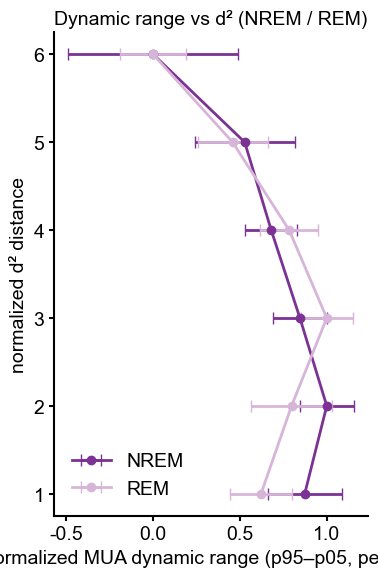

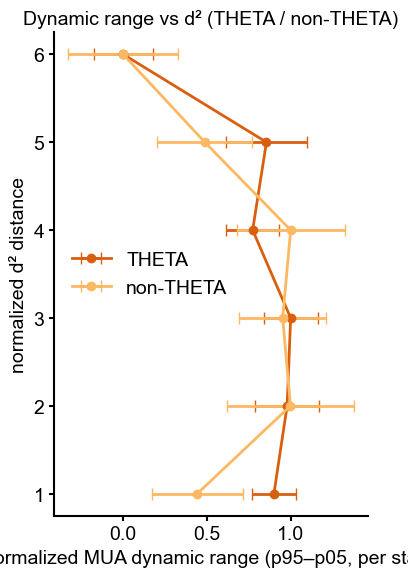

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# =======================================
# 1) Prep df_base and MUA column
# =======================================
#This function filters out sessions (files) that have too few data points
def drop_sessions_with_few_points(dstate, file_col="__file__", min_points=150):
    counts = dstate.groupby(file_col).size()
    keep_files = counts[counts >= min_points].index
    return dstate[dstate[file_col].isin(keep_files)].copy()

df_base = all_pairs.copy()
import mpmath as mp
import numpy as np
def summarize_mean_sem(df_perfile):
    """
    Aggregates over files: mean and SEM per d2_bin.
    Adds: n_animals (unique animals contributing to each bin).
    """
    if df_perfile.empty:
        return pd.DataFrame(columns=["d2_bin", "d2_center", "mean", "sem", "n_files", "n_animals"])

    g = df_perfile.groupby("d2_bin", as_index=False)
    out = g.agg(
        d2_center=("d2_center", "median"),
        mean=("dyn", "mean"),
        std=("dyn", "std"),
        n_files=("__file__", "nunique"),
        n_animals=("animal", "nunique"),
    )
    out["sem"] = out["std"] / np.sqrt(out["n_files"].clip(lower=1))
    return out

def format_p_from_logp(log_p, digits=6):
    """
    log_p: natural log(p) (<= 0, can be very negative)
    digits: significant digits for mantissa
    returns a string like '1.23e-457' without underflow
    """
    if not np.isfinite(log_p):
        return str(log_p)  # 'nan', 'inf', '-inf'

    # if p is effectively 1
    if log_p == 0:
        return "1"

    # set precision
    mp.mp.dps = digits + 50  # guard digits

    log10_p = mp.mpf(log_p) / mp.log(10)
    exp10 = int(mp.floor(log10_p))          # typically negative
    mant  = mp.power(10, log10_p - exp10)   # in [1,10)

    mant_str = mp.nstr(mant, n=digits)
    return f"{mant_str}e{exp10}"

# per-file identifier
if "__file__" not in df_base.columns:
    df_base["__file__"] = df_base["animal"].astype(str) + "_" + df_base["day"].astype(str)

# pick the MUA column name
mua_col = None
for cand in ["MUA", "mua30", "mua", "MUA30"]:
    if cand in df_base.columns:
        mua_col = cand
        break

if mua_col is None:
    raise KeyError(
        "Could not find an MUA column in all_pairs. "
        "Looked for: 'MUA', 'mua30', 'mua', 'MUA30'."
    )

print(f"Using '{mua_col}' as MUA column.")
df_base = df_base.rename(columns={mua_col: "MUA"})

# =======================================
# 2) State definitions & colors
# =======================================

state_label_sets = {
    "NREM":      {"NREM"},
    "REM":       {"REM", "REM4"},
    "THETA":     {"THETA", "Wake θ"},
    "non-THETA": {"nonTHETA", "Wake non-θ"},
}

method = "minmax"   # or 'percentile' / 'z'

colors_cond = {
    "NREM":      "#7b3294",
    "REM":       "#d7b5d8",
    "THETA":     "#d95f0e",
    "non-THETA": "#fdb863",
}

# raw summaries (for printing/stats) and per-state normalized summaries (for plotting)
summaries_raw  = {}
summaries_norm = {}

# =======================================
# 3) Per-state summaries + monotonicity
# =======================================

for label, groups in state_label_sets.items():
    mask = df_base["group"].isin(groups)
    dstate = df_base.loc[mask, ["d2", "MUA", "__file__", "animal"]].dropna()
    dstate = drop_sessions_with_few_points(dstate, file_col="__file__", min_points=15*5)

    dstate = drop_sessions_with_few_points(dstate, file_col="__file__", min_points=15*5)
    if dstate.empty:
        print(f"[WARN] {label}: all sessions dropped (not enough points).")
        continue
    print(f"{label} rows:", len(dstate))
    if dstate.empty:
        print(f"[WARN] {label}: no data, skipping.")
        continue

    # --- dynamic range per file, per d2 bin ---
    df_perfile = perfile_dyn_by_bin(dstate, method=method)
    file2animal = dstate[["__file__", "animal"]].drop_duplicates()
    df_perfile = df_perfile.merge(file2animal, on="__file__", how="left")

    df_summary = summarize_mean_sem(df_perfile)
    summaries_raw[label] = df_summary

    print(f"\n=== {label} (raw) ===")
    print(df_summary[["d2_center", "mean", "sem", "n_files"]])
    
    # --- per-state 0–1 normalization just for plotting ---
    if not df_summary.empty:
        dfN = df_summary.copy()
        m = dfN["mean"].to_numpy()
        mn = np.nanmin(m)
        mx = np.nanmax(m)

        if np.isfinite(mn) and np.isfinite(mx) and not np.isclose(mn, mx):
            dfN["mean"] = (dfN["mean"] - mn) / (mx - mn)
            dfN["sem"]  = dfN["sem"] / (mx - mn)
        else:
            # degenerate case: all values equal → set mean=0.5, sem=0
            dfN["mean"] = 0.5
            dfN["sem"]  = 0.0

        summaries_norm[label] = dfN
    else:
        summaries_norm[label] = df_summary

    # --- monotonicity test via Spearman + Stouffer meta (use RAW, not normalized) ---
    T = perfile_dyn_by_bin_no_baseline(dstate, method=method)
    res = spearman_stouffer_robust(T, alternative="decreasing")  # dyn decreasing with d2?
    p_str = format_p_from_logp(res["log_p_one_sided"], digits=6)
    per_file_rho = res["per_file"][["__file__", "rho"]]
    if res is not None:
        n_animals = dstate["animal"].nunique()  # number of animals contributing to this state

        print(
            f"{label}: z_comb = {res['z_comb']:.3f}, "
            f"rho_wmean_fisher = {res['rho_wmean_fisher']:.3f}, "
            f"p_one_sided = {p_str}, "
            f"files = {res['n_files']}, "
            f"animals = {n_animals}"
        )

    else:
        print(f"{label}: not enough bins/files for meta-analysis.")

# =======================================
# 4) Combined plots using per-state normalized dynamic range
# =======================================

# --- (A) NREM vs REM ---
plt.figure(figsize=(4, 6))
ax = plt.gca()

for label in ["NREM", "REM"]:
    if label not in summaries_norm:
        continue
    dfS = summaries_norm[label]
    if dfS.empty:
        continue

    x = dfS["mean"].to_numpy(float)           # per-state normalized MUA dynamic range
    e = dfS["sem"].to_numpy(float)
    
    # y-axis: bin index 1..6
    if "d2_bin" in dfS.columns:
        y = dfS["d2_bin"].to_numpy(int) + 1   # if 0-based
    elif "tile_num" in dfS.columns:
        y = dfS["tile_num"].to_numpy(int)     # if already 1..6
    else:
        raise KeyError("Need a bin column like 'd2_bin' or 'tile_num' in dfS to plot y=1..6.")

    ax.errorbar(
        x, y,
        xerr=e,
        fmt='-o',
        capsize=4,
        linewidth=2,
        label=label,
        color=colors_cond.get(label, "k"),
    )

ax.set_xlabel("normalized MUA dynamic range (p95–p05, per state)")
ax.set_ylabel("normalized d² distance")
ax.set_title("Dynamic range vs d² (NREM / REM)")
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(False)
plt.tight_layout()
save_path = rf"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\supplementary\figS5_rat_D__NREM_vs_REM_dyn_by_d2_{method}_norm.svg"
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

# --- (B) THETA vs non-THETA ---
plt.figure(figsize=(4, 6))
ax = plt.gca()

for label in ["THETA", "non-THETA"]:
    if label not in summaries_norm:
        continue
    dfS = summaries_norm[label]
    if dfS.empty:
        continue
    
    # x-axis: per-state normalized (or z-scored) mean dynamic range
    x = dfS["mean"].to_numpy(float)
    e = dfS["sem"].to_numpy(float)

    # y-axis: bin index 1..6
    if "d2_bin" in dfS.columns:
        y = dfS["d2_bin"].to_numpy(int) + 1   # if 0-based
    elif "tile_num" in dfS.columns:
        y = dfS["tile_num"].to_numpy(int)     # if already 1..6
    else:
        raise KeyError("Need a bin column like 'd2_bin' or 'tile_num' in dfS to plot y=1..6.")

    ax.errorbar(
        x, y,
        xerr=e,
        fmt='-o',
        capsize=4,
        linewidth=2,
        label=label,
        color=colors_cond.get(label, "k"),
    )

ax.set_xlabel("normalized MUA dynamic range (p95–p05, per state)")
ax.set_ylabel("normalized d² distance")
ax.set_title("Dynamic range vs d² (THETA / non-THETA)")
ax.legend(frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(False)
plt.tight_layout()
save_path = rf"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\supplementary\figS5_rat_D_THETA_vs_nonTHETA_dyn_by_d2_{method}_norm.svg"
plt.savefig(save_path, dpi=300, bbox_inches="tight")
plt.show()

FigS6_A

In [ ]:
import numpy as np
import pandas as pd
from pathlib import Path
import os, re, glob, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
# ---------- Summary stats ----------

# ---------- 1) Load all pickles ----------
import os, re, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nelpy as nel
import nelpy.plotting as npl
import numpy as np
import seaborn as sns
from neuro_py.io import loading
from neuro_py.plotting.figure_helpers import set_size
from neuro_py.tuning import maps
from skimage import measure
import os
import pandas as pd
import scipy.io as sio
import logging
FOLDER = r"D:\Documents\GitHub\Sleep_criticaltiy\data\rats"
files = sorted(glob.glob(os.path.join(FOLDER, "*.pkl")))
assert files, f"No .pkl files in {FOLDER}"

import os
import re

def _parse_animal_day_region_from_fname(fname):
    """
    Handles filenames without region info:
      HP17_hp17_day2_20250413.pkl -> (hp17, day2, na)
      HMC1_day10.pkl              -> (hmc1, day10, na)
    """
    base = os.path.basename(fname).lower()

    # 1. (?P<animal>[a-z0-9]+) -> Grabs the first part (e.g., hp17 or hmc1)
    # 2. .*? -> Skips any redundant middle parts (e.g., _hp17_)
    # 3. (?P<day>day\d+) -> Grabs the day (e.g., day2 or day10)
    pattern = r"^(?P<animal>[a-z0-9]+).*?(?P<day>day\d+)"
    
    m = re.search(pattern, base)
    if m:
        animal = m.group('animal')
        day = m.group('day')
        return animal, day, "na"

    # Fallback to just finding a day if the structure is weird
    m_fallback = re.search(r"(day\d+)", base)
    day = m_fallback.group(1) if m_fallback else "na"
    return "na", day, "na"
dfs = []
for f in files:
    try:
        payload = pd.read_pickle(f)

        # ---- extract the actual dataframe ----
        if isinstance(payload, pd.DataFrame):
            df = payload
        elif isinstance(payload, dict):
            # common keys
            for k in ["per_center", "results", "df", "data"]:
                if k in payload and isinstance(payload[k], pd.DataFrame):
                    df = payload[k].copy()
                    break
            else:
                raise TypeError(f"Pickle is dict but no DataFrame under known keys. Keys={list(payload.keys())[:10]}")
        else:
            raise TypeError(f"Unsupported pickle type: {type(payload)}")

        # ---- add metadata from filename if missing ----
        if not {"animal","day","region"}.issubset(df.columns):
            animal, day, region = _parse_animal_day_region_from_fname(f)
            if "animal" not in df.columns: df["animal"] = animal
            if "day"    not in df.columns: df["day"]    = day
            if "region" not in df.columns: df["region"] = region

        if "animal_day" not in df.columns:
            df["animal_day"] = df["animal"].astype(str) + "_" + df["day"].astype(str)

        # ensure these exist
        for col in ["ripple_rate", "d2_err"]:
            if col not in df.columns:
                df[col] = np.nan

        df["__file__"] = os.path.basename(f)
        dfs.append(df)

    except Exception as e:
        print(f"⚠️ Skipping {os.path.basename(f)}: {e}")

all_pairs = pd.concat(dfs, ignore_index=True)
all_pairs["group"] = all_pairs["state"].astype(str)


paths = [
r"V:\data\hpc_ctx_project\HP17\hp17_day2_20250413",
r"V:\data\hpc_ctx_project\HP17\hp17_day23_20250507",
r"V:\data\hpc_ctx_project\HP17\hp17_day26_20250510",
r"V:\data\hpc_ctx_project\HP17\hp17_day32_20250516",
r"V:\data\hpc_ctx_project\HP17\hp17_day34_20250518",
r"V:\data\hpc_ctx_project\HP17\hp17_day36_20250520",
r"V:\data\hpc_ctx_project\HP17\hp17_day40_20250526",
r"V:\data\hpc_ctx_project\HP17\hp17_day43_20250529",
r"V:\data\hpc_ctx_project\HP17\hp17_day49_20250604",
r"V:\data\hpc_ctx_project\HP15\hp15_day31_20250130",
r"V:\data\hpc_ctx_project\HP15\hp15_day35_20250205",
r"V:\data\hpc_ctx_project\HP18\hp18_day13_20250417",
r"V:\data\hpc_ctx_project\HP18\hp18_day16_20250420",
r"V:\data\hpc_ctx_project\HP18\hp18_day17_20250421",
r"V:\data\hpc_ctx_project\HP18\hp18_day36_20250510",
r"V:\data\hpc_ctx_project\HP18\hp18_day40_20250514",
r"V:\data\hpc_ctx_project\HP18\hp18_day48_20250522",
r"V:\data\hpc_ctx_project\HP18\hp18_day49_20250523",
r"V:\data\hpc_ctx_project\HP18\hp18_day51_20250525",
r"V:\data\hpc_ctx_project\HP18\hp18_day52_20250526",
r"V:\data\hpc_ctx_project\HP18\hp18_day55_20250529",
r"S:\data\latentseq\RM10\rm10_day5_20250809",
r"S:\data\latentseq\RM10\rm10_day6_20250810",
r"S:\data\latentseq\RM10\rm10_day10_20250814",
r"S:\data\latentseq\RM10\rm10_day11_20250815",
r"S:\data\latentseq\RM10\rm10_day12_20250817",
]
# ----------------------------
# paths → lookup
# ----------------------------
import numpy as np
import pandas as pd
from pathlib import Path
from pathlib import Path
import re



def session_key(p):
    """
    Normalizes strings like:
    'RM10_rm10_day6_20250810' -> 'rm10_day6'
    'V:\\...\\HP15\\hp15_day31_20250130' -> 'hp15_day31'
    """
    name = Path(p).name.lower()

    # Case 1: .../<animal>/day10
    if re.fullmatch(r"day\d+", name):
        animal = Path(p).parent.name.lower()
        return f"{animal}_{name}"

    # Case 2: Extract animal and day from complex strings
    # This looks for the first occurrence of an animal ID followed by 'day' and digits
    m = re.search(r"(?P<animal>[a-z0-9]+)_.*?day(?P<day_num>\d+)", name)
    if m:
        return f"{m.group('animal')}_day{m.group('day_num')}"

    return name
path_map = {session_key(p): Path(p) for p in paths}
all_pairs = all_pairs.copy()
all_pairs["epoch_name"]  = np.nan
all_pairs["environment"] = np.nan

keep = np.ones(len(all_pairs), dtype=bool)

# 2. Process the dataframe
for raw_key, idx_sub in all_pairs.groupby("animal_day").groups.items():
    # Clean the dataframe key so it matches the path_map keys
    clean_key = session_key(str(raw_key)) 
    
    basepath = path_map.get(clean_key)
    
    if basepath is None:
        print(f"Missing basepath for raw: '{raw_key}' (cleaned: '{clean_key}')")
        continue

    print(f"Processing {clean_key} at {basepath}")
    epoch_df = loading.load_epoch(str(basepath))

    name = epoch_df["name"].astype(str).str.lower()
    env  = epoch_df.get("environment", pd.Series("", index=epoch_df.index)).astype(str)

    # ----------------------------
    # (A) Annotate environment + epoch_name for ALL rows
    # ----------------------------
    times_all = all_pairs.loc[idx_sub, "center_s"].to_numpy(float)

    for _, row in epoch_df.iterrows():
        t0 = float(row["startTime"])
        t1 = float(row["stopTime"])

        in_epoch = (times_all >= t0) & (times_all <= t1)
        if not in_epoch.any():
            continue

        # annotate environment (always)
        all_pairs.loc[idx_sub[in_epoch], "environment"] = row.get("environment")

        # annotate epoch_name if present
        if "name" in row and pd.notna(row["name"]):
            all_pairs.loc[idx_sub[in_epoch], "epoch_name"] = row["name"]

    # ----------------------------
    # Identify TASK epochs
    # ----------------------------
    is_sleep = env.astype(str).str.lower().str.contains("sleep") | name.str.contains("sleep")

    is_tmaze = (
        env.astype(str).str.lower().str.contains("cheeseboard")
        | env.astype(str).str.lower().str.contains("linear")
        | env.astype(str).str.lower().str.contains("t-maze")
        | env.astype(str).str.lower().str.contains("task")
        | name.str.contains("maze")
        | name.str.contains("cheeseboard")
        | name.str.contains("t-maze")
        | name.str.startswith("freet")
        | name.str.startswith("t_")
    )

    task_epochs = epoch_df[is_tmaze & ~is_sleep].copy()

    # ----------------------------
    # (B) KEEP ONLY wake points that are IN task epochs
    # ----------------------------
    wake_idx = idx_sub[
        all_pairs.loc[idx_sub, "group"]
        .isin(["Wake θ", "Wake non-θ"])
        .to_numpy()
    ]

    if task_epochs.empty:
        # no task epochs => drop all wake points
        keep[wake_idx] = False
    else:
        times_wake = all_pairs.loc[wake_idx, "center_s"].to_numpy(float)

        in_any_task = np.zeros(times_wake.shape[0], dtype=bool)
        for _, row in task_epochs.iterrows():
            t0 = float(row["startTime"])
            t1 = float(row["stopTime"])
            in_any_task |= (times_wake >= t0) & (times_wake <= t1)

        # drop wake points NOT in task
        keep[wake_idx[~in_any_task]] = False

    # ----------------------------
    # (C) If manipulation non-empty → remove NREM / REM
    # ----------------------------
    if "manipulation" in epoch_df.columns:
        manip = epoch_df["manipulation"].astype(str).str.lower().str.strip()
        sil_epochs = epoch_df[manip == "pfc_silence"]

        if not sil_epochs.empty:
            # only drop NREM/REM points that fall inside pfc_silence epochs
            times_all = all_pairs.loc[idx_sub, "center_s"].to_numpy(float)
            is_sleep_row = all_pairs.loc[idx_sub, "group"].isin(["NREM", "REM"]).to_numpy()

            in_sil = np.zeros(times_all.shape[0], dtype=bool)
            for _, row in sil_epochs.iterrows():
                t0 = float(row["startTime"])
                t1 = float(row["stopTime"])
                in_sil |= (times_all >= t0) & (times_all <= t1)

            # drop = (sleep row) AND (time inside pfc_silence epoch)
            to_drop = is_sleep_row & in_sil
            keep[idx_sub[to_drop]] = False

# ----------------------------
# Final cleaned dataframe
# ----------------------------
all_pairs_clean = all_pairs.loc[keep].copy()

Processing hp15_day31 at V:\data\hpc_ctx_project\HP15\hp15_day31_20250130
Processing hp15_day35 at V:\data\hpc_ctx_project\HP15\hp15_day35_20250205
Processing hp17_day2 at V:\data\hpc_ctx_project\HP17\hp17_day2_20250413
Processing hp17_day23 at V:\data\hpc_ctx_project\HP17\hp17_day23_20250507
Processing hp17_day26 at V:\data\hpc_ctx_project\HP17\hp17_day26_20250510
Processing hp17_day32 at V:\data\hpc_ctx_project\HP17\hp17_day32_20250516
Processing hp17_day34 at V:\data\hpc_ctx_project\HP17\hp17_day34_20250518
Processing hp17_day36 at V:\data\hpc_ctx_project\HP17\hp17_day36_20250520


C:\Users\Cornell\AppData\Local\Temp\ipykernel_39128\3898150976.py:197: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'sleep' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
C:\Users\Cornell\AppData\Local\Temp\ipykernel_39128\3898150976.py:201: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'hp15_presleep_250130_102336' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.


Processing hp17_day40 at V:\data\hpc_ctx_project\HP17\hp17_day40_20250526
Processing hp17_day43 at V:\data\hpc_ctx_project\HP17\hp17_day43_20250529
Processing hp17_day49 at V:\data\hpc_ctx_project\HP17\hp17_day49_20250604
Processing hp18_day13 at V:\data\hpc_ctx_project\HP18\hp18_day13_20250417
Processing hp18_day16 at V:\data\hpc_ctx_project\HP18\hp18_day16_20250420
Processing hp18_day17 at V:\data\hpc_ctx_project\HP18\hp18_day17_20250421
Processing hp18_day36 at V:\data\hpc_ctx_project\HP18\hp18_day36_20250510
Processing hp18_day40 at V:\data\hpc_ctx_project\HP18\hp18_day40_20250514
Processing hp18_day48 at V:\data\hpc_ctx_project\HP18\hp18_day48_20250522
Processing hp18_day49 at V:\data\hpc_ctx_project\HP18\hp18_day49_20250523
Processing hp18_day51 at V:\data\hpc_ctx_project\HP18\hp18_day51_20250525
Processing hp18_day52 at V:\data\hpc_ctx_project\HP18\hp18_day52_20250526
Processing rm10_day10 at S:\data\latentseq\RM10\rm10_day10_20250814
Processing rm10_day11 at S:\data\latentseq\R

In [ ]:
from pathlib import Path
import pandas as pd
def presleep_is_first_session(path, loader):
    """
    Returns True if an epoch whose name contains 'presleep'
    is the earliest epoch in the session.
    """
    try:
        epoch_df = loader(str(path))
    except Exception as e:
        print(f"[FAIL] {path}: could not load epoch_df ({e})")
        return False

    if epoch_df is None or epoch_df.empty:
        return False

    if "startTime" not in epoch_df.columns or "name" not in epoch_df.columns:
        print(f"[WARN] {path}: epoch_df missing startTime or name")
        return False
    
    # normalize
    name = epoch_df["name"].astype(str).str.lower()
  
    presleep_mask = name.str.contains("presleep")
    if not presleep_mask.any():
        return False  # no presleep at all
    
    # earliest start overall
    t_first = epoch_df["startTime"].min()

    # earliest presleep start
    t_presleep = epoch_df.loc[presleep_mask, "startTime"].min()

    # presleep is first session iff it starts first
    return np.isclose(t_presleep, t_first)


paths_with_presleep_first = []

for p in paths:
    if presleep_is_first_session(p, loading.load_epoch):
        paths_with_presleep_first.append(p)

print("Sessions where presleep is first:")
for p in paths_with_presleep_first:
    print(p)

Sessions where presleep is first:
V:\data\hpc_ctx_project\HP17\hp17_day2_20250413
V:\data\hpc_ctx_project\HP17\hp17_day23_20250507
V:\data\hpc_ctx_project\HP17\hp17_day40_20250526
V:\data\hpc_ctx_project\HP17\hp17_day43_20250529
V:\data\hpc_ctx_project\HP18\hp18_day16_20250420
V:\data\hpc_ctx_project\HP18\hp18_day51_20250525
V:\data\hpc_ctx_project\HP18\hp18_day52_20250526
S:\data\latentseq\RM10\rm10_day10_20250814
S:\data\latentseq\RM10\rm10_day12_20250817


FigS6_A

C:\Users\Cornell\AppData\Local\Temp\ipykernel_39128\1674358178.py:147: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

C:\Users\Cornell\AppData\Local\Temp\ipykernel_39128\1674358178.py:166: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



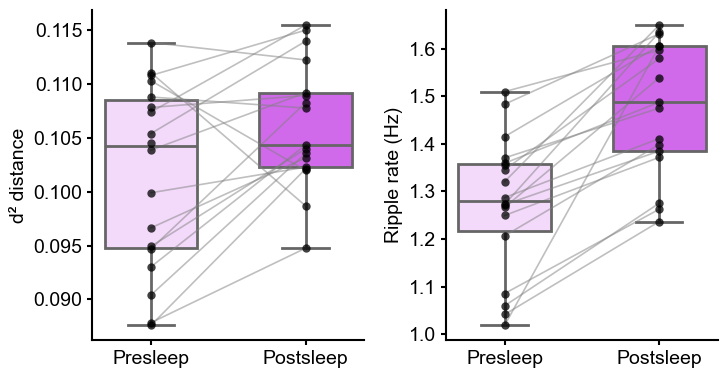

Saved: D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan\rats\fig2_A_pre_vs_postsleep_perfile_paired.svg


In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl

# Global font: prefer Arial, with safe fallbacks
mpl.rcParams['svg.fonttype'] = 'none' 
mpl.rcParams['text.usetex'] = False
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = [
    'Helvetica Neue', 'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
]

# Mathtext to match
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Helvetica Neue'   # or 'Helvetica'
mpl.rcParams['mathtext.it'] = 'Helvetica Neue:italic'
mpl.rcParams['mathtext.bf'] = 'Helvetica Neue:bold'

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
# ------------------------------
# 1) File-aware epoch selection
# ------------------------
# 1) File-aware epoch selection
# ------------------------
tmp = all_pairs_clean.copy()
tmp["sleep_epoch"] = tmp["sleep_epoch"].astype(str).str.lower()

keep_rows = []

WINDOW_SIZE=300

for file_id, g in tmp.groupby("animal_day"):

    g_nrem = g[g["state"].astype(str).str.upper() == "NREM"]
    if g_nrem.empty:
        continue

    # --- always keep presleep ---
    out = [g_nrem[g_nrem["sleep_epoch"] == "presleep"]]

    # --- prefer midsleep ---
    g_mid = g_nrem[g_nrem["sleep_epoch"] == "midsleep"]
    if not g_mid.empty:
        out.append(g_mid)
    else:
        # --- otherwise take ONLY FIRST postsleep block ---
        g_post = g_nrem[g_nrem["sleep_epoch"] == "postsleep"]
        if not g_post.empty:
            # find first postsleep block by time
            g_post = g_post.sort_values("center_s")

            # define block as contiguous in time
            # gap threshold = 2× window size (adjust if needed)
            dt = np.diff(g_post["center_s"].values)
            cut = np.where(dt > 2 * WINDOW_SIZE)[0]

            if len(cut) > 0:
                first_block_end = cut[0] + 1
                g_post = g_post.iloc[:first_block_end]

            out.append(g_post)

    keep_rows.append(pd.concat(out, axis=0))


plot_df = pd.concat(keep_rows, ignore_index=True)

# ------------------------
# 2) Relabel epochs → Pre vs Postsleep
# ------------------------
def relabel(ep):
    if ep == "presleep":
        return "Presleep"
    else:
        return "Postsleep"   # midsleep or postsleep fallback

plot_df["epoch2"] = plot_df["sleep_epoch"].map(relabel)

# ------------------------
# 3) Per-file mean per epoch
# ------------------------
summary_df = (
    plot_df.groupby(["animal_day", "epoch2"], as_index=False)[["d2", "ripple_rate_30s"]]
            .mean()
)

# ------------------------
# 4) Helper for paired lines
# ------------------------
def draw_paired_lines(ax, df_pair, y_col, order):
    """
    df_pair: per-file summary
    y_col: "d2" or "ripple_rate_30s"
    order: ["Pre", "Postsleep"]
    """
    pivot = df_pair.pivot(index="animal_day", columns="epoch2", values=y_col)
    pivot = pivot.dropna()   # keep only paired files

    for file_id, row in pivot.iterrows():
        ax.plot(
            [order[0], order[1]],
            [row[order[0]], row[order[1]]],
            color="gray", alpha=0.5, linewidth=1.2,
            zorder=2
        )

# ------------------------
# 5) Plot (two panels): d² and ripple rate
# ------------------------
order = ["Presleep", "Postsleep"]
palette = {"Presleep": "#f6d5ffff", "Postsleep": "#dd55ffff"}

fig, axes = plt.subplots(1, 2, figsize=(7.5, 4))

# -------- D² panel --------
ax = axes[0]


sns.boxplot(
    data=summary_df, x="epoch2", y="d2",
    order=order, palette=palette,
    showfliers=False, width=0.6, linewidth=2, ax=ax, zorder=2
)

sns.stripplot(
    data=summary_df, x="epoch2", y="d2",
    order=order, color="k", jitter=False,
    alpha=0.75, size=6, ax=ax, zorder=3
)
draw_paired_lines(ax, summary_df, y_col="d2", order=order)
ax.set_xlabel("")
ax.set_ylabel("d² distance")


# -------- Ripple rate panel --------
ax = axes[1]

sns.boxplot(
    data=summary_df, x="epoch2", y="ripple_rate_30s",
    order=order, palette=palette,
    showfliers=False, width=0.6, linewidth=2, ax=ax, zorder=2
)

sns.stripplot(
    data=summary_df, x="epoch2", y="ripple_rate_30s",
    order=order, color="k", jitter=False,
    alpha=0.75, size=6, ax=ax, zorder=3
)

ax.set_xlabel("")
ax.set_ylabel("Ripple rate (Hz)")
draw_paired_lines(ax, summary_df, y_col="ripple_rate_30s", order=order)


# Aesthetics
for ax in axes:
    sns.despine(ax=ax)
    ax.grid(False)
    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(False)

plt.tight_layout()

save_path = r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan\rats\fig2_A_pre_vs_postsleep_perfile_paired.svg"
plt.savefig(save_path, dpi=300)
plt.show()

print("Saved:", save_path)

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy.stats import norm

# ----------------------------
# 0) Start from plot_df
#    columns needed: animal, animal_day, epoch2, d2, ripple_rate
# ----------------------------

# 1) Aggregate to session means: one row per (animal_day, epoch2)
df_m = (
    plot_df
    .groupby(["animal", "animal_day", "epoch2"], as_index=False)
    .agg(
        d2_mean=("d2", "mean"),
        ripple_mean=("ripple_rate", "mean"),
        n_windows=("d2", "size")
    )
)

# 2) Keep only paired animal_day (must have both epochs)
paired_days = (
    df_m.groupby(["animal_day", "epoch2"]).size()
        .unstack("epoch2")
        .dropna()
        .index
)
df_m = df_m[df_m["animal_day"].isin(paired_days)].copy()

# 3) Set reference so coef is Presleep - Postsleep
df_m["epoch2"] = pd.Categorical(df_m["epoch2"], categories=["Postsleep", "Presleep"])

# ----------------------------
# 4) LMM: fixed epoch2; random intercept by animal; VC for animal_day
# ----------------------------
vc = {"animal_day": "0 + C(animal_day)"}  # session/day-specific random intercept

res_ripple = smf.mixedlm(
    "ripple_mean ~ epoch2",
    df_m,
    groups=df_m["animal"],     # random intercept for animal
    vc_formula=vc,
    re_formula="1"
).fit(reml=False, method="lbfgs")

print(res_ripple.summary())

term = "epoch2[T.Presleep]"
beta = res_ripple.params[term]
z = res_ripple.tvalues[term]   # for MixedLM this is typically treated as z (Wald)

# underflow-safe two-sided p:
logp = np.log(2) + norm.logsf(abs(z))
neglog10p = -logp / np.log(10)

print("Epoch effect (Presleep - Postsleep):", beta)
print(f"z={z:.4g}, -log10(p)={neglog10p:.3f}, log(p)={logp:.3f}")
if logp < -745:
    print("p underflows in float64; report as p < 5e-324 (or report -log10(p)).")
else:
    print("p =", float(np.exp(logp)))

            Mixed Linear Model Regression Results
Model:              MixedLM  Dependent Variable:  ripple_mean
No. Observations:   34       Method:              ML         
No. Groups:         2        Scale:               0.0072     
Min. group size:    16       Log-Likelihood:      23.9940    
Max. group size:    18       Converged:           Yes        
Mean group size:    17.0                                     
-------------------------------------------------------------
                   Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------------
Intercept           1.480    0.053 27.693 0.000  1.375  1.584
epoch2[T.Presleep] -0.211    0.029 -7.215 0.000 -0.268 -0.153
Group Var           0.004    0.064                           
animal_day Var      0.008    0.071                           

Epoch effect (Presleep - Postsleep): -0.210692948935321
z=-7.215, -log10(p)=12.267, log(p)=-28.245
p = 5.410240173492154e-13


c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.


FigS6_6 replay nonreplay

N files per tile:
      IN   OUT
1  15.0  15.0
2  15.0  15.0
3  15.0  15.0
4  15.0  15.0
5  15.0  15.0
6  15.0  15.0


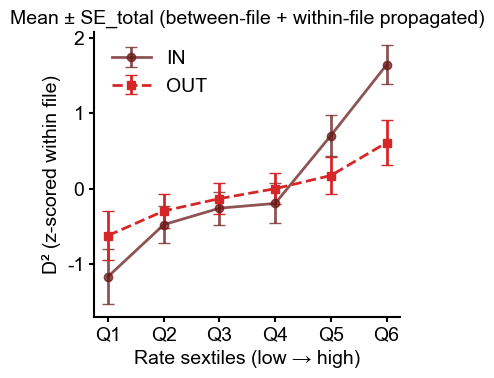

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import sem

# ----------------------------
# 1) Load all *_tile.pkl files
# ----------------------------
def load_all_tile_pkls(tile_dir, pattern="*_tile.pkl"):
    tile_dir = Path(tile_dir)
    files = sorted(tile_dir.glob(pattern))
    if not files:
        # fallback pattern: *_df_tile.pkl
        files = sorted(tile_dir.glob("*_df_tile.pkl"))
    if not files:
        raise FileNotFoundError(f"No tile pkls found in {tile_dir} (patterns: {pattern}, *_df_tile.pkl)")

    all_long = []
    for fp in files:
        df = pd.read_pickle(fp).copy()
        df["file_id"] = fp.name

        # ---- required columns ----
        need = {"tile_num", "in_d2_mean", "in_d2_sem", "out_d2_mean", "out_d2_lo", "out_d2_hi"}
        missing = need - set(df.columns)
        if missing:
            raise ValueError(f"{fp.name} missing columns: {missing}")

        # long format
        in_long = pd.DataFrame({
            "file_id": df["file_id"],
            "tile_num": df["tile_num"].astype(int),
            "group": "IN",
            "d2_mean": df["in_d2_mean"].astype(float),
            "d2_se": df["in_d2_sem"].astype(float),   # within-file SE for IN
        })

        # OUT: approximate within-file SE from 95% CI width (assumes ~normal bootstrap dist)
        out_se = (df["out_d2_hi"].astype(float) - df["out_d2_lo"].astype(float)) / (2 * 1.96)

        out_long = pd.DataFrame({
            "file_id": df["file_id"],
            "tile_num": df["tile_num"].astype(int),
            "group": "OUT",
            "d2_mean": df["out_d2_mean"].astype(float),
            "d2_se": out_se.astype(float),            # within-file SE approx for OUT
        })

        long = pd.concat([in_long, out_long], ignore_index=True)
        all_long.append(long)

    long_all = pd.concat(all_long, ignore_index=True)
    return long_all

# ------------------------------------------
# 2) Z-score within each file (propagate SE)
# ------------------------------------------
def zscore_within_file(long_all):
    """
    Z-score d2_mean within each file using BOTH groups & all tiles together:
      z = (d2_mean - mu_file) / sd_file
    Propagate SE: z_se = d2_se / sd_file
    """
    x = long_all.copy()

    # compute file-level mu/sd from all (group,tile) entries
    stats = (
        x.groupby("file_id", observed=True)["d2_mean"]
         .agg(mu="mean", sd=lambda v: np.nanstd(v.to_numpy(float), ddof=0))
         .reset_index()
    )
    stats["sd"] = stats["sd"].where(np.isfinite(stats["sd"]) & (stats["sd"] > 0), 1.0)

    x = x.merge(stats, on="file_id", how="left")
    x["d2_z"] = (x["d2_mean"] - x["mu"]) / x["sd"]
    x["d2_z_se"] = x["d2_se"] / x["sd"]   # SE scales by 1/sd for z-score
    return x

# -------------------------------------------------------
# 3) Mean + SEM across files, with within-file propagation
# -------------------------------------------------------
def summarize_across_files(zlong, n_bins=6):
    """
    For each (group, tile_num):
      - mean across files of d2_z (file is unit)
      - SEM_between across files
      - SE_total = sqrt(SEM_between^2 + mean(within_se^2)/N_files)
    """
    # file-level point estimate per (file,group,tile): already single row per file/tile in df_tile
    # But just in case, aggregate
    file_level = (
        zlong.groupby(["file_id","group","tile_num"], observed=True)
             .agg(d2_z=("d2_z","mean"), d2_z_se=("d2_z_se","mean"))
             .reset_index()
    )

    tiles = range(1, n_bins + 1)
    out_mean = pd.DataFrame(index=list(tiles), columns=["IN","OUT"], dtype=float)
    out_sem_between = pd.DataFrame(index=list(tiles), columns=["IN","OUT"], dtype=float)
    out_se_total = pd.DataFrame(index=list(tiles), columns=["IN","OUT"], dtype=float)
    out_nfiles = pd.DataFrame(index=list(tiles), columns=["IN","OUT"], dtype=float)

    for grp in ["IN","OUT"]:
        for t in tiles:
            sub = file_level[(file_level["group"] == grp) & (file_level["tile_num"] == t)]
            if sub.empty:
                continue

            vals = sub["d2_z"].to_numpy(float)
            vals = vals[np.isfinite(vals)]
            N = vals.size
            out_nfiles.loc[t, grp] = N
            if N == 0:
                continue

            m = float(np.nanmean(vals))
            out_mean.loc[t, grp] = m

            # between-file SEM (file is unit)
            out_sem_between.loc[t, grp] = float(sem(vals, nan_policy="omit")) if N >= 2 else np.nan

            # within-file propagation term
            within = sub["d2_z_se"].to_numpy(float)
            within = within[np.isfinite(within)]
            within_term = float(np.sqrt(np.nanmean(within**2)) / np.sqrt(N)) if within.size else 0.0

            se_between = out_sem_between.loc[t, grp]
            if np.isfinite(se_between):
                out_se_total.loc[t, grp] = float(np.sqrt(se_between**2 + within_term**2))
            else:
                out_se_total.loc[t, grp] = np.nan

    return file_level, out_mean, out_sem_between, out_se_total, out_nfiles

# ----------------------------
# 4) Plot helper
# ----------------------------
def plot_mean_sem(mean_df, err_df, n_bins=6, title=None, ylabel="D² (z-scored within file)",colors=None):
    xs = np.arange(1, n_bins + 1)
    fig, ax = plt.subplots(figsize=(4,4))

    for grp, fmt in [("IN","o-"), ("OUT","s--")]:
        y = mean_df.get(grp)
        e = err_df.get(grp)
        if y is None:
            continue
        ax.errorbar(xs, y.values, yerr=e.values if e is not None else None,
                    fmt=fmt, capsize=4, lw=2, label=grp,color=colors.get(grp) if colors else None)

    ax.set_xticks(xs)
    ax.set_xticklabels([f"Q{i}" for i in xs])
    ax.set_xlabel("Rate sextiles (low → high)")
    ax.set_ylabel(ylabel)
    if title:
        ax.set_title(title)
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(frameon=False)
    plt.tight_layout()
    save_path = r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\individual_fig_main\figS6_C_rat_replay_non_replay_mean_sem_across_files.svg"
    plt.savefig(save_path, dpi=300)
    plt.show()

# ----------------------------
# RUN
# ----------------------------
tile_dir = Path(r"D:\Documents\GitHub\Sleep_criticaltiy\data\rats\replay_nonreplay")  # change
long_all = load_all_tile_pkls(tile_dir, pattern="*_tile.pkl")
zlong = zscore_within_file(long_all)

file_level, mean_z, sem_between, se_total, nfiles = summarize_across_files(zlong, n_bins=6)

print("N files per tile:\n", nfiles)

# # Plot 1: SEM across files only (between-file variability)
# plot_mean_sem(mean_z, sem_between, n_bins=6,
#               title="Mean ± SEM across files (between-file only)")

# Plot 2: Total SE = between-file SEM + propagated within-file uncertainty

colors={"IN":"#691c1bc0", "OUT":"#d62728ff"}
plot_mean_sem(mean_z, se_total, n_bins=6,
              title="Mean ± SE_total (between-file + within-file propagated)",colors=colors)


=== Linear trend tests on tile means ===
IN : {'a': -1.7465268704187906, 'b': 0.5106588670431471, 'se_a': 0.34392115048939204, 'se_b': 0.08704112179207982, 't_b': 5.866869090485617, 'p_b': 0.004214687481554957, 'r2': 0.8958879729651446, 'n': 6}
OUT: {'a': -0.724790131942329, 'b': 0.19498793573488535, 'se_a': 0.08971385416908788, 'se_b': 0.025932165823511284, 't_b': 7.519153512357244, 'p_b': 0.0016746540720267156, 'r2': 0.9339254379919792, 'n': 6}
Slope difference (OUT-IN): -0.315671 ± 0.0798899, t=-3.95, p=0.00423 (**), n_points=12


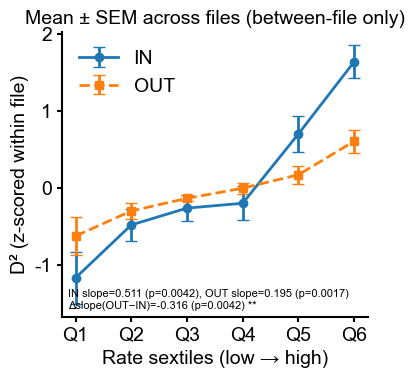

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import t as t_dist

def _wls_fit_line(x, y, se=None):
    """
    Weighted least squares line fit: y = a + b*x
    Returns dict with a,b, SEs, t/p for slope, and weighted R^2.
    """
    x = np.asarray(x, float)
    y = np.asarray(y, float)

    ok = np.isfinite(x) & np.isfinite(y)
    if se is not None:
        se = np.asarray(se, float)
        ok = ok & np.isfinite(se) & (se > 0)

    x = x[ok]; y = y[ok]
    if se is None:
        w = np.ones_like(y)
    else:
        se = se[ok]
        w = 1.0 / (se**2)

    n = len(y)
    if n < 3:
        return dict(a=np.nan, b=np.nan, se_a=np.nan, se_b=np.nan, t_b=np.nan, p_b=np.nan, r2=np.nan, n=n)

    X = np.column_stack([np.ones(n), x])
    W = np.diag(w)

    XtWX = X.T @ W @ X
    XtWy = X.T @ W @ y
    beta = np.linalg.solve(XtWX, XtWy)  # [a,b]

    yhat = X @ beta
    resid = y - yhat

    # weighted residual variance
    dof = n - 2
    rss_w = float(resid.T @ W @ resid)
    s2 = rss_w / dof if dof > 0 else np.nan

    cov = s2 * np.linalg.inv(XtWX) if np.isfinite(s2) else np.full((2,2), np.nan)
    se_a = np.sqrt(cov[0,0]) if np.isfinite(cov[0,0]) else np.nan
    se_b = np.sqrt(cov[1,1]) if np.isfinite(cov[1,1]) else np.nan

    t_b = beta[1] / se_b if np.isfinite(se_b) and se_b > 0 else np.nan
    p_b = 2 * (1 - t_dist.cdf(abs(t_b), dof)) if np.isfinite(t_b) and dof > 0 else np.nan

    # weighted R^2
    ybar_w = np.sum(w * y) / np.sum(w)
    tss_w = np.sum(w * (y - ybar_w)**2)
    r2 = 1 - (rss_w / tss_w) if tss_w > 0 else np.nan

    return dict(a=float(beta[0]), b=float(beta[1]), se_a=float(se_a), se_b=float(se_b),
                t_b=float(t_b), p_b=float(p_b), r2=float(r2), n=n)

def slope_difference_test(mean_df, err_df=None, n_bins=6):
    """
    Weighted interaction test comparing slopes:
      y = a + b*x + c*g + d*(x*g), g=1 for OUT, 0 for IN
    Tests H0: d = 0 (same slope).
    Returns dict with per-group fits and slope-diff p-value.
    """
    xs = np.arange(1, n_bins + 1, dtype=float)

    def _extract(grp):
        y = mean_df.get(grp)
        if y is None: 
            return xs, np.full_like(xs, np.nan), None
        yv = np.asarray(y.reindex(range(1, n_bins+1)).values, float)
        if err_df is None or err_df.get(grp) is None:
            return xs, yv, None
        ev = np.asarray(err_df.get(grp).reindex(range(1, n_bins+1)).values, float)
        return xs, yv, ev

    x_in,  y_in,  e_in  = _extract("IN")
    x_out, y_out, e_out = _extract("OUT")

    fit_in  = _wls_fit_line(x_in,  y_in,  e_in)
    fit_out = _wls_fit_line(x_out, y_out, e_out)

    # build pooled design for interaction test (use whatever points are finite)
    X_list, y_list, w_list = [], [], []

    def _append_group(x, y, e, gval):
        for xi, yi, ei in zip(x, y, (e if e is not None else [np.nan]*len(y))):
            if not (np.isfinite(xi) and np.isfinite(yi)):
                continue
            if e is not None:
                if not (np.isfinite(ei) and ei > 0):
                    continue
                wi = 1.0 / (ei**2)
            else:
                wi = 1.0

            # [1, x, g, x*g]
            X_list.append([1.0, xi, float(gval), float(gval)*xi])
            y_list.append(float(yi))
            w_list.append(float(wi))

    _append_group(x_in,  y_in,  e_in,  0)
    _append_group(x_out, y_out, e_out, 1)

    X = np.asarray(X_list, float)
    y = np.asarray(y_list, float)
    w = np.asarray(w_list, float)

    n = len(y)
    if n < 6:  # need enough points for 4 params
        return dict(fit_in=fit_in, fit_out=fit_out, slope_diff=np.nan, se_slope_diff=np.nan, t=np.nan, p=np.nan, n=n)

    W = np.diag(w)
    XtWX = X.T @ W @ X
    XtWy = X.T @ W @ y
    beta = np.linalg.solve(XtWX, XtWy)  # [a, b, c, d]
    yhat = X @ beta
    resid = y - yhat

    dof = n - 4
    rss_w = float(resid.T @ W @ resid)
    s2 = rss_w / dof if dof > 0 else np.nan
    cov = s2 * np.linalg.inv(XtWX) if np.isfinite(s2) else np.full((4,4), np.nan)

    d = float(beta[3])                 # slope_OUT - slope_IN
    se_d = float(np.sqrt(cov[3,3])) if np.isfinite(cov[3,3]) else np.nan
    t = d / se_d if np.isfinite(se_d) and se_d > 0 else np.nan
    p = 2 * (1 - t_dist.cdf(abs(t), dof)) if np.isfinite(t) and dof > 0 else np.nan

    return dict(fit_in=fit_in, fit_out=fit_out, slope_diff=d, se_slope_diff=se_d, t=t, p=p, n=n)

def _p_to_stars(p):
    if not np.isfinite(p): return "n/a"
    if p < 1e-3: return "***"
    if p < 1e-2: return "**"
    if p < 5e-2: return "*"
    return "ns"

def plot_mean_sem(mean_df, err_df, n_bins=6, title=None, ylabel="D² (z-scored within file)", do_slope_test=True):
    xs = np.arange(1, n_bins + 1)
    fig, ax = plt.subplots(figsize=(4,4))

    for grp, fmt in [("IN","o-"), ("OUT","s--")]:
        y = mean_df.get(grp)
        e = err_df.get(grp) if err_df is not None else None
        if y is None:
            continue
        ax.errorbar(xs, y.reindex(range(1, n_bins+1)).values,
                    yerr=e.reindex(range(1, n_bins+1)).values if e is not None else None,
                    fmt=fmt, capsize=4, lw=2, label=grp)

    ax.set_xticks(xs)
    ax.set_xticklabels([f"Q{i}" for i in xs])
    ax.set_xlabel("Rate sextiles (low → high)")
    ax.set_ylabel(ylabel)
    if title:
        ax.set_title(title)
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    # ---- slope tests ----
    if do_slope_test:
        res = slope_difference_test(mean_df, err_df=err_df, n_bins=n_bins)
        p = res["p"]
        stars = _p_to_stars(p)

        fin = res["fit_in"]; fout = res["fit_out"]
        txt = (
            f"IN slope={fin['b']:.3g} (p={fin['p_b']:.2g}), "
            f"OUT slope={fout['b']:.3g} (p={fout['p_b']:.2g})\n"
            f"Δslope(OUT−IN)={res['slope_diff']:.3g} (p={p:.2g}) {stars}"
        )
        # put text inside axes
        ax.text(0.02, 0.02, txt, transform=ax.transAxes, ha="left", va="bottom", fontsize=8)

        # also print full numeric info
        print("=== Linear trend tests on tile means ===")
        print("IN :", fin)
        print("OUT:", fout)
        print(f"Slope difference (OUT-IN): {res['slope_diff']:.6g} ± {res['se_slope_diff']:.6g}, "
              f"t={res['t']:.3g}, p={p:.3g} ({stars}), n_points={res['n']}")

    ax.legend(frameon=False)
    plt.tight_layout()
    plt.show()
plot_mean_sem(mean_z, sem_between, n_bins=6,
              title="Mean ± SEM across files (between-file only)")  

S6_E_branching_ratio

Unique file counts per condition:
condition
Barrage            11
Barrage_Shuffle    11
Ripple             11
Ripple_Shuffle     11
Name: file, dtype: int64


C:\Users\Cornell\AppData\Local\Temp\ipykernel_51976\1602190590.py:171: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



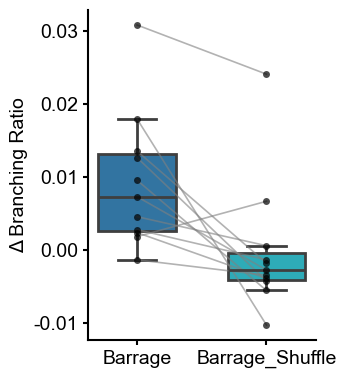

In [32]:

import matplotlib.pyplot as plt
import nelpy as nel
import nelpy.plotting as npl
import numpy as np
import seaborn as sns
from neuro_py.io import loading
from neuro_py.plotting.figure_helpers import set_size
from neuro_py.tuning import maps
from skimage import measure
import os
import logging
import pickle
import pandas as pd
import matplotlib as mpl
# Global font: prefer Arial, with safe fallbacks
mpl.rcParams['svg.fonttype'] = 'none' 
mpl.rcParams['text.usetex'] = False
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = [
    'Helvetica Neue', 'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
]

# Mathtext to match
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Helvetica Neue'   # or 'Helvetica'
mpl.rcParams['mathtext.it'] = 'Helvetica Neue:italic'
mpl.rcParams['mathtext.bf'] = 'Helvetica Neue:bold'

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
# --- Step 1: Load all files ---
base_dir = r"D:\Documents\GitHub\Sleep_criticaltiy\data\rats\branching_ratio\ripple_barr\branching_ratio"
files = [f for f in os.listdir(base_dir) if f.endswith("_br_changes_non_overlap.pkl")]

all_rows = []

# --- Step 2: Extract results ---
import numpy as np

all_rows = []

for fname in files:
    fpath = os.path.join(base_dir, fname)
    with open(fpath, "rb") as f:
        payload = pickle.load(f)

    results = payload["results"] if isinstance(payload, dict) and "results" in payload else payload

    parts = fname.split("_")
    animal = parts[0]
    day = parts[1]

    # Collect all values first (for normalization)
    file_values = []
    for key in ["ripples_br_changes", "ripples_br_changes_shuffle",
                "barrage_br_changes", "barrage_br_changes_shuffle"]:
        if key in results:
            file_values.extend(results[key])

    file_values = np.array(file_values, dtype=float)
    mean_val = np.nanmean(file_values)
    std_val  = np.nanstd(file_values)

    # Avoid div by zero
    if std_val == 0:
        std_val = 1.0

    # Now add normalized rows
    for key, label in [
        ("ripples_br_changes", "Ripple"),
        ("ripples_br_changes_shuffle", "Ripple_Shuffle"),
        ("barrage_br_changes", "Barrage"),
        ("barrage_br_changes_shuffle", "Barrage_Shuffle"),
    ]:
        if key in results:
            vals = results[key]
            for v in vals:
                v_norm = v # z-score normalization
                all_rows.append({
                    "animal": animal,
                    "day": day,
                    "condition": label,
                    "value": v_norm
                })

# --- Step 3: Build dataframe ---
df = pd.DataFrame(all_rows)
df["file"] = df["animal"].astype(str) + "_" + df["day"].astype(str)

# --- Compute per-file mean per condition ---
pf = (
    df.groupby(["file", "condition"], observed=True)["value"]
      .mean()
      .rename("file_mean")
      .reset_index()
)

print("Unique file counts per condition:")
print(pf.groupby("condition")["file"].nunique())
df["file"] = df["animal"].astype(str) + "_" + df["day"].astype(str)

pf = (
    df.groupby(["file", "condition"], observed=True)["value"]
      .mean()
      .rename("file_mean")
      .reset_index()
)
# Ripple subset
pf_ripple = pf[pf["condition"].isin(["Ripple", "Ripple_Shuffle"])].copy()
def draw_paired_lines(ax, df_pair, order, color="gray", alpha=0.5):
    """
    df_pair must contain columns: file, condition, file_mean
    """
    # Pivot to file → [cond1, cond2]
    pivot = df_pair.pivot_table(index="file", columns="condition", values="file_mean", observed=True)

    # Keep only files that have both conditions
    pivot = pivot.dropna()

    # Draw connecting lines
    for file_id, row in pivot.iterrows():
        ax.plot(
            [order[0], order[1]],
            [row[order[0]], row[order[1]]],
            color=color, alpha=alpha, linewidth=1.2
        )

# Barrage subset
pf_barrage = pf[pf["condition"].isin(["Barrage", "Barrage_Shuffle"])].copy()
pal_ripple = {"Ripple": "tab:red", "Ripple_Shuffle": "tab:orange"}
order_ripple = ["Ripple", "Ripple_Shuffle"]

pal_barrage = {"Barrage": "tab:blue", "Barrage_Shuffle": "tab:cyan"}
order_barrage = ["Barrage", "Barrage_Shuffle"]


# print(f"Saved Ripple plot with paired lines: {save_path1}")

plt.figure(figsize=(3.5,4))
ax = plt.gca()

# --- Paired lines ---


# --- Boxplot ---
sns.boxplot(
    data=pf_barrage, x="condition", y="file_mean",
    order=order_barrage, palette=pal_barrage,
    showfliers=False, width=0.6, linewidth=2, ax=ax
)

# --- Points ---
sns.stripplot(
    data=pf_barrage, x="condition", y="file_mean",jitter=False,
    order=order_barrage, color="k", alpha=0.7
    , size=5, ax=ax
)

ax.set_xlabel("")
ax.set_ylabel(r"Δ Branching Ratio")
sns.despine(top=True, right=True)
plt.tight_layout()
draw_paired_lines(ax, pf_barrage, order_barrage, color="gray", alpha=0.6)
save_path2 = r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\supplementary\individual_fig_supp\figS6E_rat_barrage_br_changes_perfile_paired.svg"
plt.savefig(save_path2, dpi=300)
plt.show()

In [33]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy.stats import norm

df = df.copy()
df["animal"] = df["animal"].astype(str)
df["day"]    = df["day"].astype(str)
df["animal_day"] = df["animal"] + "_" + df["day"]

# -----------------------------
# 1) Collapse to session means
# -----------------------------
mean_df = (
    df.groupby(["animal", "animal_day", "condition"], as_index=False)
      .agg(value_mean=("value", "mean"),
           n_windows=("value", "size"))
)

# optional: drop condition-cells with too few windows
MIN_WINDOWS = 5
mean_df = mean_df[mean_df["n_windows"] >= MIN_WINDOWS].copy()

# optional: keep only sessions that have all conditions (pairing)
# e.g., for Ripple vs Ripple_Shuffle:
conds_need = ["Ripple", "Ripple_Shuffle", "Barrage", "Barrage_Shuffle"]  # edit as needed
pivot = mean_df.pivot_table(index="animal_day", columns="condition", values="value_mean", aggfunc="first")
keep_sessions = pivot.dropna(subset=[c for c in conds_need if c in pivot.columns], how="any").index
mean_df = mean_df[mean_df["animal_day"].isin(keep_sessions)].copy()

# IMPORTANT: set reference level so contrasts are interpretable
mean_df["condition"] = pd.Categorical(
    mean_df["condition"],
    categories=[c for c in conds_need if c in mean_df["condition"].unique()] +
               [c for c in mean_df["condition"].unique() if c not in conds_need],
    ordered=True
)

# -----------------------------
# 2) Mean-level LMM
#   random: animal_day + animal
# -----------------------------
model = smf.mixedlm(
    "value_mean ~ C(condition)",
    data=mean_df,
    groups=mean_df["animal_day"],
    vc_formula={"animal": "0 + C(animal)"}   # animal-level intercept
)
res = model.fit(method="lbfgs")
print(res.summary())

# -----------------------------
# 3) Contrasts on fixed effects
# -----------------------------
fe = res.fe_params
cov_fe = res.cov_params().loc[fe.index, fe.index]
def _p_to_stars(p):
    if not np.isfinite(p): return "n/a"
    if p < 1e-3: return "***"
    if p < 1e-2: return "**"
    if p < 5e-2: return "*"
    return "ns"
def contrast_test(coeffs: dict, label: str):
    c = np.zeros(len(fe))
    for i, name in enumerate(fe.index):
        if name in coeffs:
            c[i] = coeffs[name]
    diff = float(c @ fe.values)
    se   = float(np.sqrt(c @ cov_fe.values @ c))
    z    = diff / se
    p    = 2 * norm.sf(abs(z))
    print(f"{label}: diff={diff:.6g}, z={z:.3f}, p={p:.4g} {_p_to_stars(p)}")
    return diff, p


# Example: Barrage vs Barrage_Shuffle
contrast_test(
    {"C(condition)[T.Barrage]": 1, "C(condition)[T.Barrage_Shuffle]": -1},
    "Barrage vs Barrage_Shuffle"
)


                  Mixed Linear Model Regression Results
Model:                  MixedLM       Dependent Variable:       value_mean
No. Observations:       44            Method:                   REML      
No. Groups:             11            Scale:                    0.0000    
Min. group size:        4             Log-Likelihood:           128.8518  
Max. group size:        4             Converged:                Yes       
Mean group size:        4.0                                               
--------------------------------------------------------------------------
                                Coef.  Std.Err.   z    P>|z| [0.025 0.975]
--------------------------------------------------------------------------
Intercept                       -0.002    0.006 -0.389 0.697 -0.015  0.010
C(condition)[T.Ripple_Shuffle]   0.006    0.002  2.545 0.011  0.001  0.010
C(condition)[T.Barrage]          0.012    0.002  5.442 0.000  0.008  0.016
C(condition)[T.Barrage_Shuffle]  0.002    0.

c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1533: RuntimeWarning: divide by zero encountered in log
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1537: RuntimeWarning: divide by zero encountered in divide
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1542: RuntimeWarning: divide by zero encountered in divide
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:573: RuntimeWarning: invalid value encountered in scalar add
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1741: RuntimeWarning: divide by zero encountered in divide
c:\Users\Cornell\.conda\e

(0.009458787323947813, 1.2744652898959362e-05)